<a href="https://colab.research.google.com/github/cmauriciocrescente-upc/Dataset-en-Colab/blob/main/Actividad_02_11_26_Crescente_Mauricio_Bias_vs_Varianza.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Alumno: Crescente Mauricio


# Bias vs Varianza

Fuente:https://medium.com/@nicolasarrioja/gu%C3%ADa-definitiva-a-bias-variance-tradeoff-94fb5c118d0f


Uno de los conceptos más importantes para poder obtener un óptimo resultado de nuestro modelo es el Bias-Variance tradeoff, por lo que es importante comprenderlo.

Este concepto también es conocido como Compensación Bias-Varianza.

Cuando creamos un modelo de machine learning deseamos que sea lo más eficiente posible para obtener los mejores resultados, pero para lograrlo tenemos que lograr un balance entre el Bias y Variance. Esto nos lleva a la compensación Bias-Variance.

Tanto Bias como Variance son errores en nuestro modelo y buscamos reducirlos, pero no resulta tan sencillo. Cuando logramos reducir Bias notaremos que Variance incrementa, si reducimos variance entonces Bias incrementa. Esto nos lleva a una situación de balance donde ambos deben de ser lo mas pequeños posibles.


## Bias: Es la diferencia entre la predicción esperada de nuestro modelo y los valores verdaderos.

El Bias o sesgo en un modelo de machine learning es muy fácil de entender, simplemente es un tipo de error que indica la diferencia que existe entre la predicción del modelo y el valor actual. Si lo vemos desde la perspectiva de la estadística es la tendencia a sobrestimar o subestimar un parámetro. Si el modelo tiene un Bias alto significa que le presta poca atención a los datos y sobre simplifica el modelo. Esto nos lleva a tener un error alto tanto en training como en test.

Para usar los términos más formales de sesgo y varianza, supongamos que tenemos un estimador puntual $\hat{θ}$ de algún parámetro o función $θ$. Entonces, el sesgo comúnmente se define como la diferencia entre el valor esperado del estimador y el parámetro que queremos estimar:

$$ Bias = E[\hat{θ}]- θ $$





## Variance: Se refiere a la cantidad que la estimación de la función objetivo cambiará si se utiliza diferentes datos de entrenamiento.

Variance o varianza también se considera un error en el modelo de machine learning que tenemos. Este error lo podemos entender como que tan sensible es nuestro modelo a los datos. Si tenemos exceso de sensibilidad el modelo puede creer ver patrones que realmente no existen ahí. En el contexto de estadística es una medida de dispersión de los datos, es la distancia de cada variable a la media de todas las variables. Si tenemos un valor de Variance alto esto significa que el modelo le presta mucha atención a los datos de entrenamiento y no va a generalizar bien en datos que no ha visto. Esto lo podemos ver cuando en el entrenamiento el modelo funciona muy bien pero tiene mucho error en el test.

$$ Variance = E[(E[\hat{θ}]- \hat{θ})^2] $$






No es posible seleccionar uno sobre otro para reducir, ya que si nos concentramos en uno en particular el modelo puede generar overfit o underfit. En ambos casos nuestro modelo va a tener problemas. La única opción que tenemos es encontrar el punto donde ambos puedan ser lo más pequeños posible.

Tenemos que tomar en cuenta que existe otro tipo de error que no puede ser reducido al crear modelos, sin importar que tan buenos sean. Este error se conoce como error irreductible y simplemente es un medida de la cantidad de ruido que tenemos en nuestros datos. El error total el modelo será:

http://rasbt.github.io/mlxtend/user_guide/evaluate/bias_variance_decomp/


$$ Error = [Bias]^2 + Varianza + ErrorIrreductible$$




Podemos entender esto más fácilmente en la siguiente imagen.


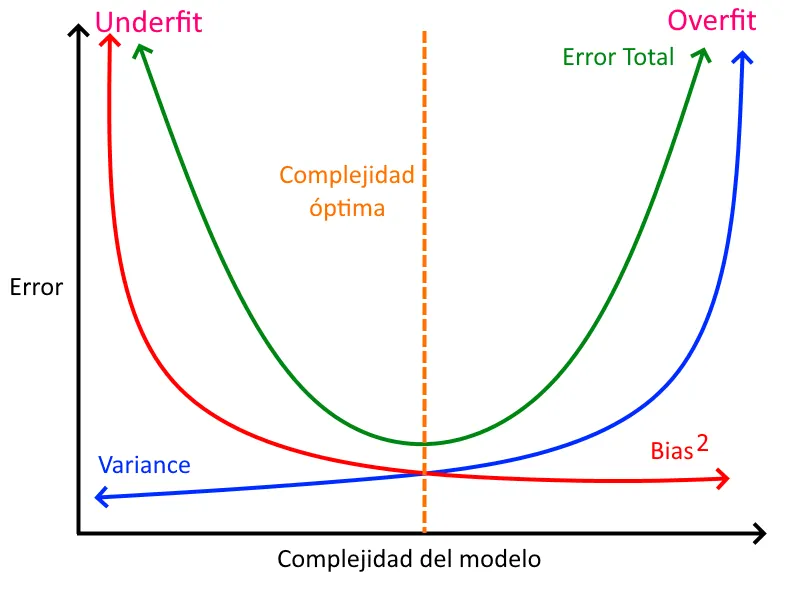

Una imagen clásica para explicar este concepto consiste de cuatro blancos (dianas) donde podemos ver el efecto de Bias y Variance.

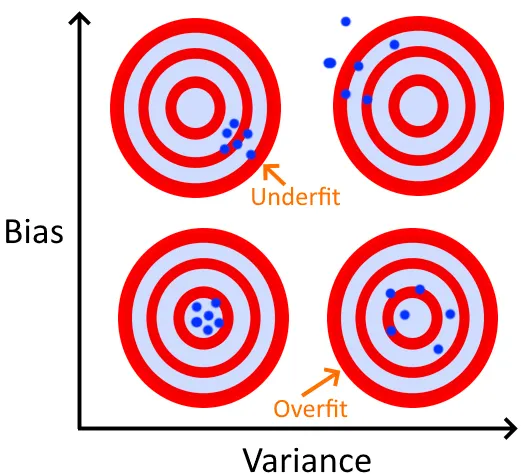

Al observar la imagen podemos entender el comportamiento de cada tipo de error. Si el Bias es pequeño nos encontramos cerca del centro, pero si se incrementa nos alejamos de él. Con la varianza podemos observar que si el valor es pequeño los puntos se encuentran cercanos entre sí, pero al aumentar los puntos se encuentran dispersos. Solamente si bajamos el error en ambos podemos tener los mejores resultados.

Al bajar el Bias y Variance reducimos el error total del modelo, lo que nos acerca a tener un modelo óptimo. Al lograr esto tenemos un modelo que no es muy complejo o muy sencillo. ¿Por qué es esto importante? Si tenemos un modelo complejo tendemos a tener overfitting, pero si tenemos un modelo sencillo lo que lograremos es underfitting.



La curva verde nos indica como se modifica el valor del error al cambiar el valor de Bias o de Variance. Si observamos hay un punto donde el error total del modelo es más bajo. En ese punto el valor de Bias y Variance nos permite tener la complejidad óptima del modelo, lo que significa que tendremos el menor error. Todo este concepto es la compensación Bias-Variance o Bias-Variance tradeoff.



Es importante conocer que puede producir el underfitting y el overfitting ahora que ya tenemos los conceptos de Bias y Variance claros.

## ¿Cuando sucede el underfitting?

Puede suceder cuando tenemos una cantidad baja de parámetros en el modelo y no se puede capturar la esencia de los datos de entrenamiento.

Cuando tenemos un Bias alto y Variance bajo.

También puede ocasionarse cuando tenemos tan pocos datos que no se puede construir un modelo adecuado.

Si intentamos construir un modelo lineal cuando los datos no son lineales también surge este problema.



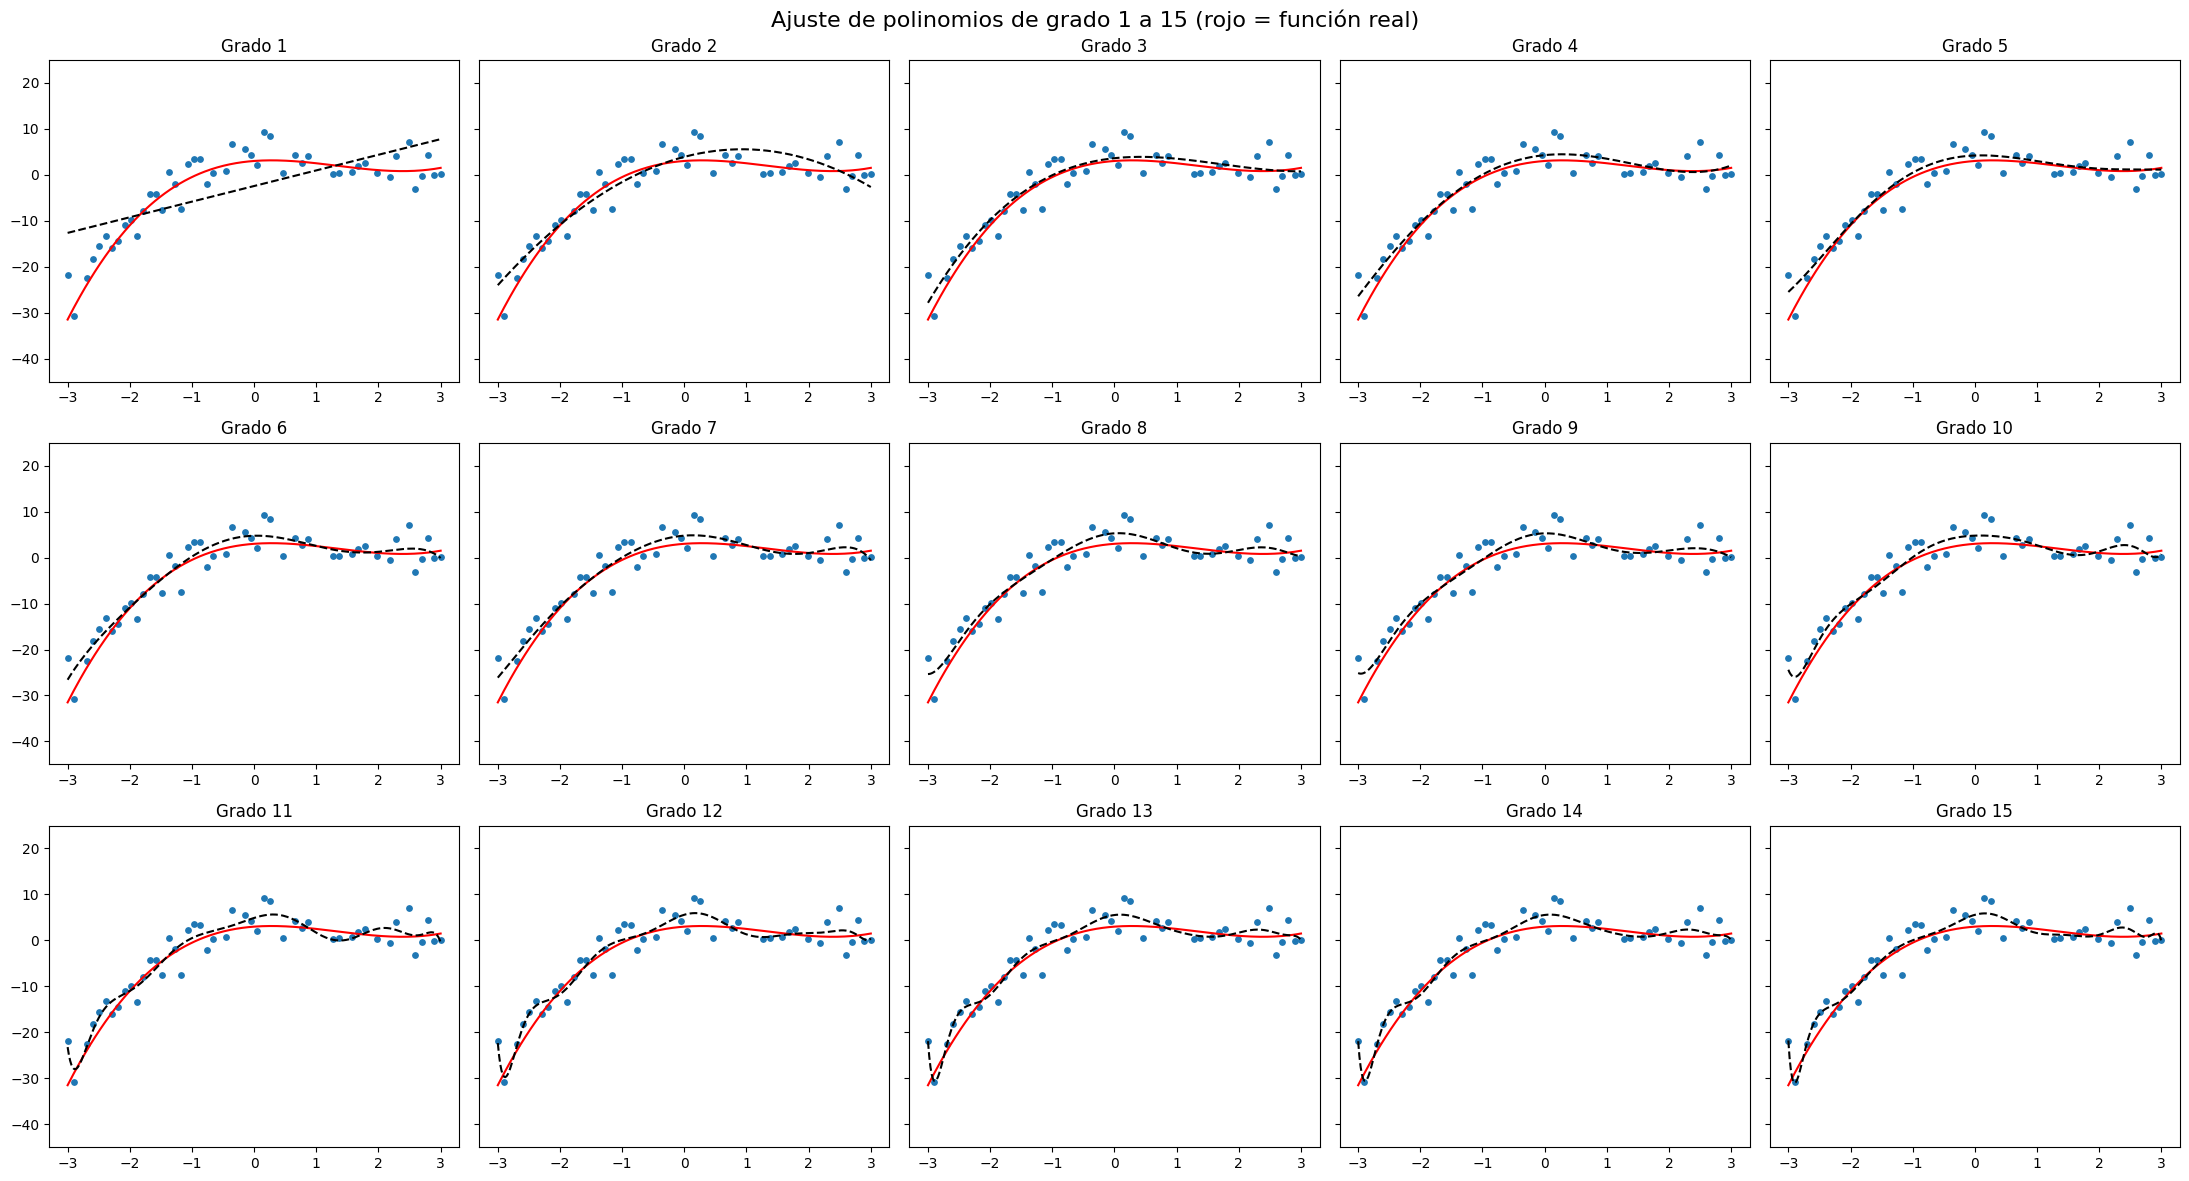

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Definimos las constantes y funciones necesarias para que la celda sea autocontenida
NUM_OBS = 60
SIGMA = 3.0

def f_verdadera(x):
    """Función real que genera los datos (polinomio de grado 3)."""
    return 0.5 * x**3 - 2 * x**2 + x + 3

# Regeneramos explícitamente los datos de la regresión cúbica para evitar que variables globales sobrescritas causen conflicto
x_reg = np.linspace(-3, 3, NUM_OBS)             # 60 valores
eps_reg = np.random.normal(0, SIGMA, NUM_OBS)   # ruido
y_reg = f_verdadera(x_reg) + eps_reg            # y = f(x) + ruido

# Ahora realizamos la división de entrenamiento y prueba de manera segura
x_train_reg, x_test_reg, y_train_reg, y_test_reg = train_test_split(
    x_reg, y_reg,          # datos limpios y consistentes de la regresión cúbica
    test_size=0.2,         # 20% para test
    random_state=1         # semilla para consistencia
)

x_plot = np.linspace(-3, 3, 300)                          # malla fina de x para dibujar curvas suaves

fig, axs = plt.subplots(3, 5, figsize=(22, 12), sharey=True)   # cuadrícula de 3 filas x 5 columnas (15 grados)

for ax, g in zip(axs.ravel(), range(1, 16)):              # recorre cada panel junto con su grado (1 a 15)
    coef = np.polyfit(x_train_reg, y_train_reg, deg=g)    # ajusta polinomio con datos correctos de train
    y_curva = np.polyval(coef, x_plot)                    # evalúa el polinomio en la malla fina

    ax.scatter(x_train_reg, y_train_reg, s=15, c='tab:blue')  # puntos de entrenamiento
    ax.plot(x_plot, f_verdadera(x_plot), 'r-', lw=1.5)    # función real (referencia)
    ax.plot(x_plot, y_curva, 'k--', lw=1.5)               # modelo ajustado
    ax.set_ylim(-45, 25)                                  # fija el eje y para comparar paneles entre sí
    ax.set_title(f'Grado {g}')                            # título con el grado del polinomio

fig.suptitle('Ajuste de polinomios de grado 1 a 15 (rojo = función real)', fontsize=16)  # título general
plt.tight_layout()                                        # acomoda los paneles para que no se superpongan
plt.show()                                                # muestra la figura


## ¿Cuando sucede el overfitting?

Cuando tenemos muchos predictores o parámetros lo cual ocasiona que se capture el ruido junto con el patrón de los datos. Esto hace que el modelo se ajuste mucho a los datos de entrenamiento perdiendo generalidad para poder trabajar con datos no vistos.

Si tenemos un valor bajo de Bias y alto de Variance.

Si tenemos un modelo muy complejo para representar datos más sencillos.

Observemos este comportamiento en un modelo real. A continuación ajustamos polinomios de
grado 1 a 15 sobre los datos de entrenamiento y los comparamos con la función verdadera (línea roja).

El **grado** del polinomio indica la complejidad del modelo. Podemos observar que para
grados 1 y 2 el modelo no se ajusta bien a los datos: tenemos **underfitting**. Para grados
altos (de 10 a 15) el modelo exagera el ajuste a los datos de entrenamiento: tenemos **overfitting**.
Los demás parecen tener un ajuste adecuado, pero ¿cuál es el mejor? Eso lo sabremos al
observar el error total de todos los modelos.

### ¿Cuál es el mejor grado?  Comparando el error de train y de test
El valor de P indica el grado del polinomio que estamos usando para crear el modelo. Podemos observar que para P=1 y P=2, el modelo no se ajusta bien a los datos, tenemos underfitting. En el caso de P=11 hasta P=15, el modelo trata de exagerar el ajuste a los datos lo que nos indica overfitting. Los demás modelos parecen tener un ajuste adecuado, pero ¿cuál es el mejor?, eso lo podemos saber si observamos el error total de todos los modelos.

Para saber cuál es el mejor modelo, observamos el **error total** (MSE) de todos los grados
sobre los conjuntos de train y de test. Ese gráfico se genera en la celda siguiente: el mejor
modelo es el que tiene el **menor error de test**.

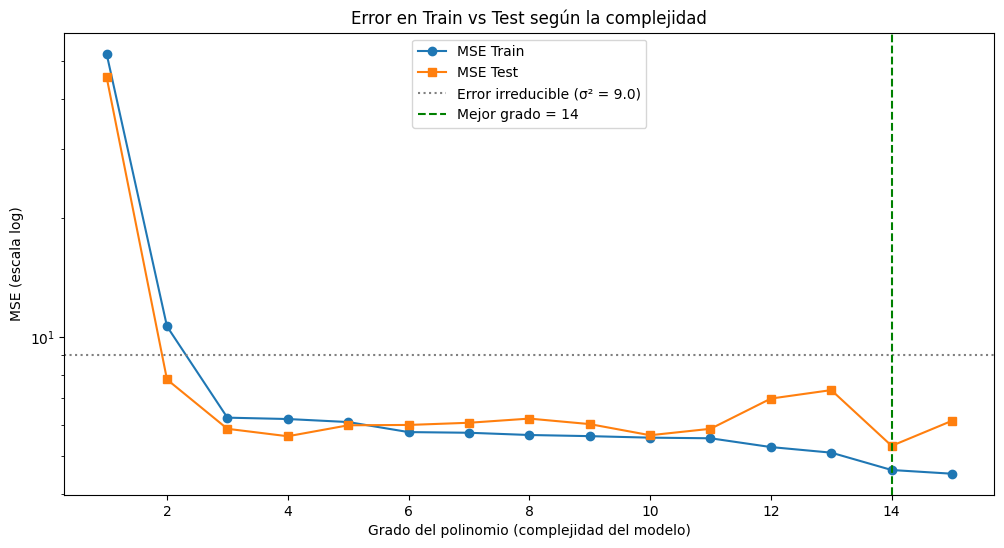

Mejor grado según el MSE de test: 14


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Regeneramos los datos de regresión cúbica para garantizar que tengan la misma longitud y no choquen con variables de otros bloques
x_reg = np.linspace(-3, 3, NUM_OBS)
eps_reg = np.random.normal(0, SIGMA, NUM_OBS)
y_reg = f_verdadera(x_reg) + eps_reg

x_train_reg, x_test_reg, y_train_reg, y_test_reg = train_test_split(
    x_reg, y_reg,
    test_size=0.2,
    random_state=1
)

grados = range(1, 16)       # grados a evaluar: 1, 2, ..., 15
train_mse = []              # lista para guardar el error en train de cada grado
test_mse = []               # lista para guardar el error en test de cada grado

for g in grados:                                                 # recorre cada grado
    coef = np.polyfit(x_train_reg, y_train_reg, deg=g)           # ajusta el polinomio solo con datos de train
    y_train_pred = np.polyval(coef, x_train_reg)                 # predicciones sobre train
    y_test_pred = np.polyval(coef, x_test_reg)                   # predicciones sobre test (datos no vistos)
    train_mse.append(mean_squared_error(y_train_reg, y_train_pred))  # guarda el MSE de train
    test_mse.append(mean_squared_error(y_test_reg, y_test_pred))     # guarda el MSE de test

mejor_grado = list(grados)[int(np.argmin(test_mse))]             # grado con menor MSE de test

fig = plt.figure(figsize=(12, 6))                                # nueva figura
plt.plot(grados, train_mse, 'o-', label='MSE Train')             # curva del error de entrenamiento
plt.plot(grados, test_mse, 's-', label='MSE Test')               # curva del error de prueba
plt.axhline(SIGMA**2, color='gray', ls=':', label=f'Error irreducible (σ² = {SIGMA**2:.1f})')  # piso teórico del error
plt.axvline(mejor_grado, color='green', ls='--', label=f'Mejor grado = {mejor_grado}')         # marca el mejor grado
plt.yscale('log')                                                # escala log: el error explota con grados altos
plt.xlabel('Grado del polinomio (complejidad del modelo)')       # eje x
plt.ylabel('MSE (escala log)')                                   # eje y
plt.title('Error en Train vs Test según la complejidad')         # título
plt.legend()                                                     # leyenda
plt.show()                                                       # muestra el gráfico

print("Mejor grado según el MSE de test:", mejor_grado)          # imprime el grado óptimo

## Como atender estos errores

https://colab.research.google.com/github/goodboychan/chans_jupyter/blob/master/_notebooks/2020-06-03-02-The-Bias-Variance-Tradeoff.ipynb


## Ejemplo en regresión lineal

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from random import randint
from math import pi as PI
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

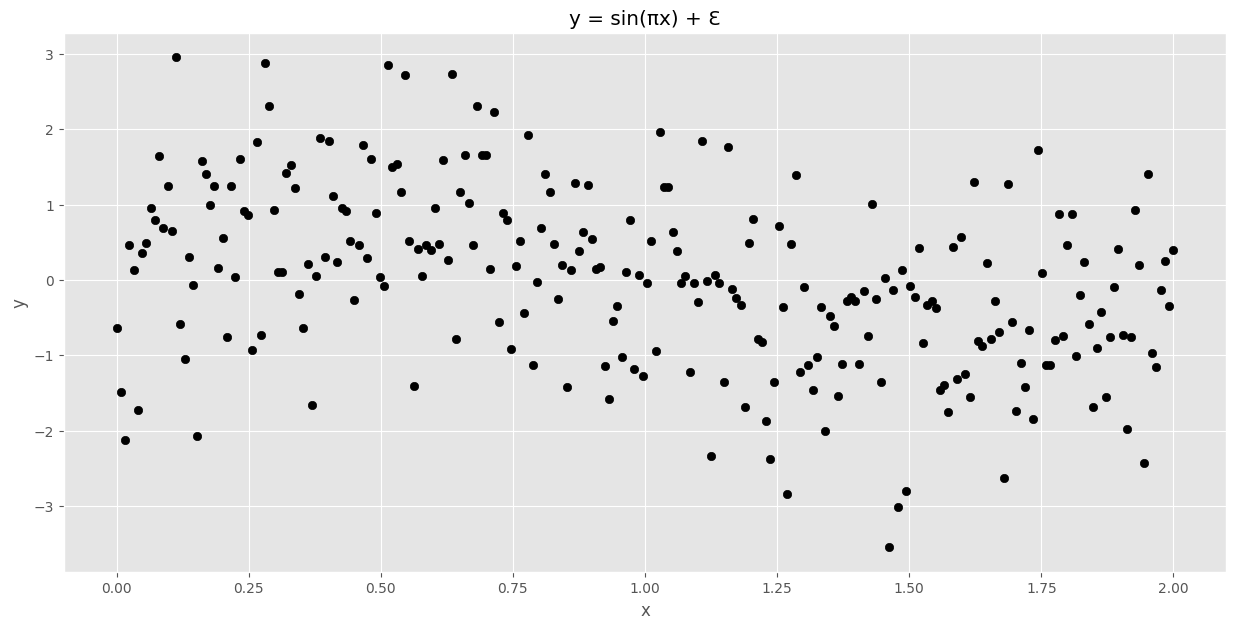

In [ ]:

plt.style.use('ggplot')

# for reproducibility across different runs, one may set a seed as follows:
# np.random.seed(42)

# number of observations
NUM_OBS = 250

# predictors
x = np.linspace(0, 2, num = NUM_OBS)
# noise
eps = np.random.normal(0, 1, NUM_OBS)
# outcome
y = np.sin(PI*x) + eps

fig = plt.figure(figsize=(15,7))
ax = plt.axes()
ax.set_title('y = sin(πx) + Ɛ')
ax.set_xlabel("x")
ax.set_ylabel("y")

ax.scatter(x, y, c = 'k')

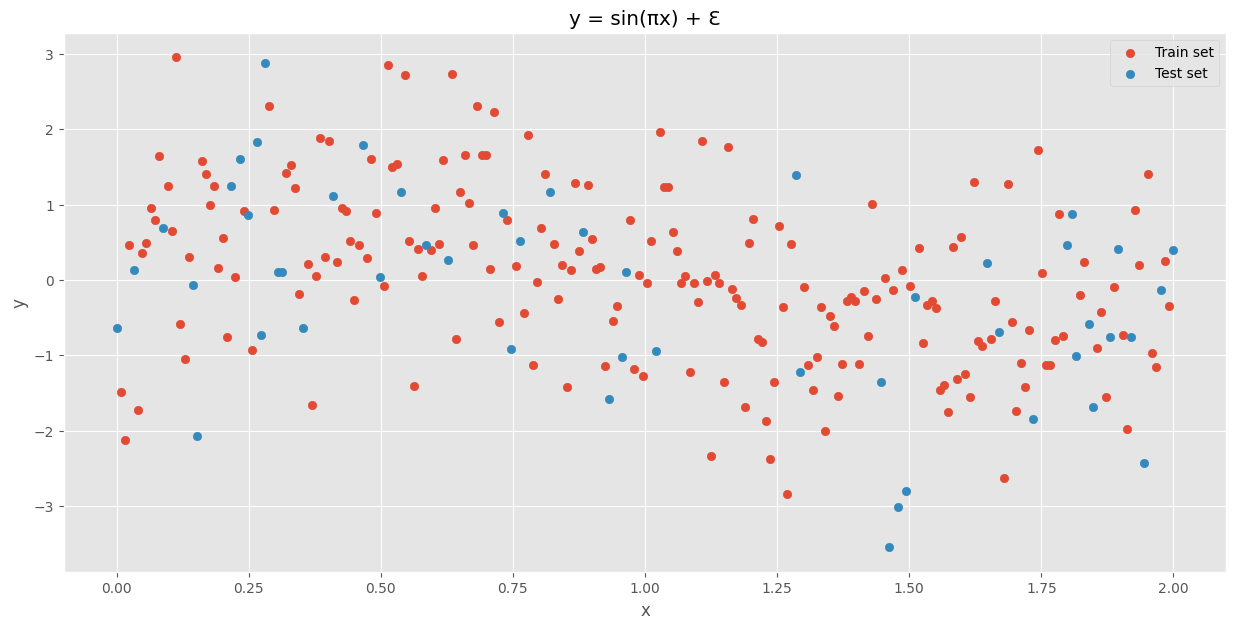

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x,
                                                    y,
                                                    test_size = 0.2,
                                                    random_state = 1)

fig = plt.figure(figsize = (15,7))
ax = plt.axes()
ax.set_title('y = sin(πx) + Ɛ')
ax.set_xlabel("x")
ax.set_ylabel("y")

ax.scatter(x_train, y_train, label = "Train set")
ax.scatter(x_test, y_test, label = "Test set")
ax.legend()

/tmp/ipykernel_576/637303437.py:37: RankWarning: Polyfit may be poorly conditioned
  fit_coeff = np.polyfit(x_train, y_train, deg = k+1)
/tmp/ipykernel_576/637303437.py:37: RankWarning: Polyfit may be poorly conditioned
  fit_coeff = np.polyfit(x_train, y_train, deg = k+1)


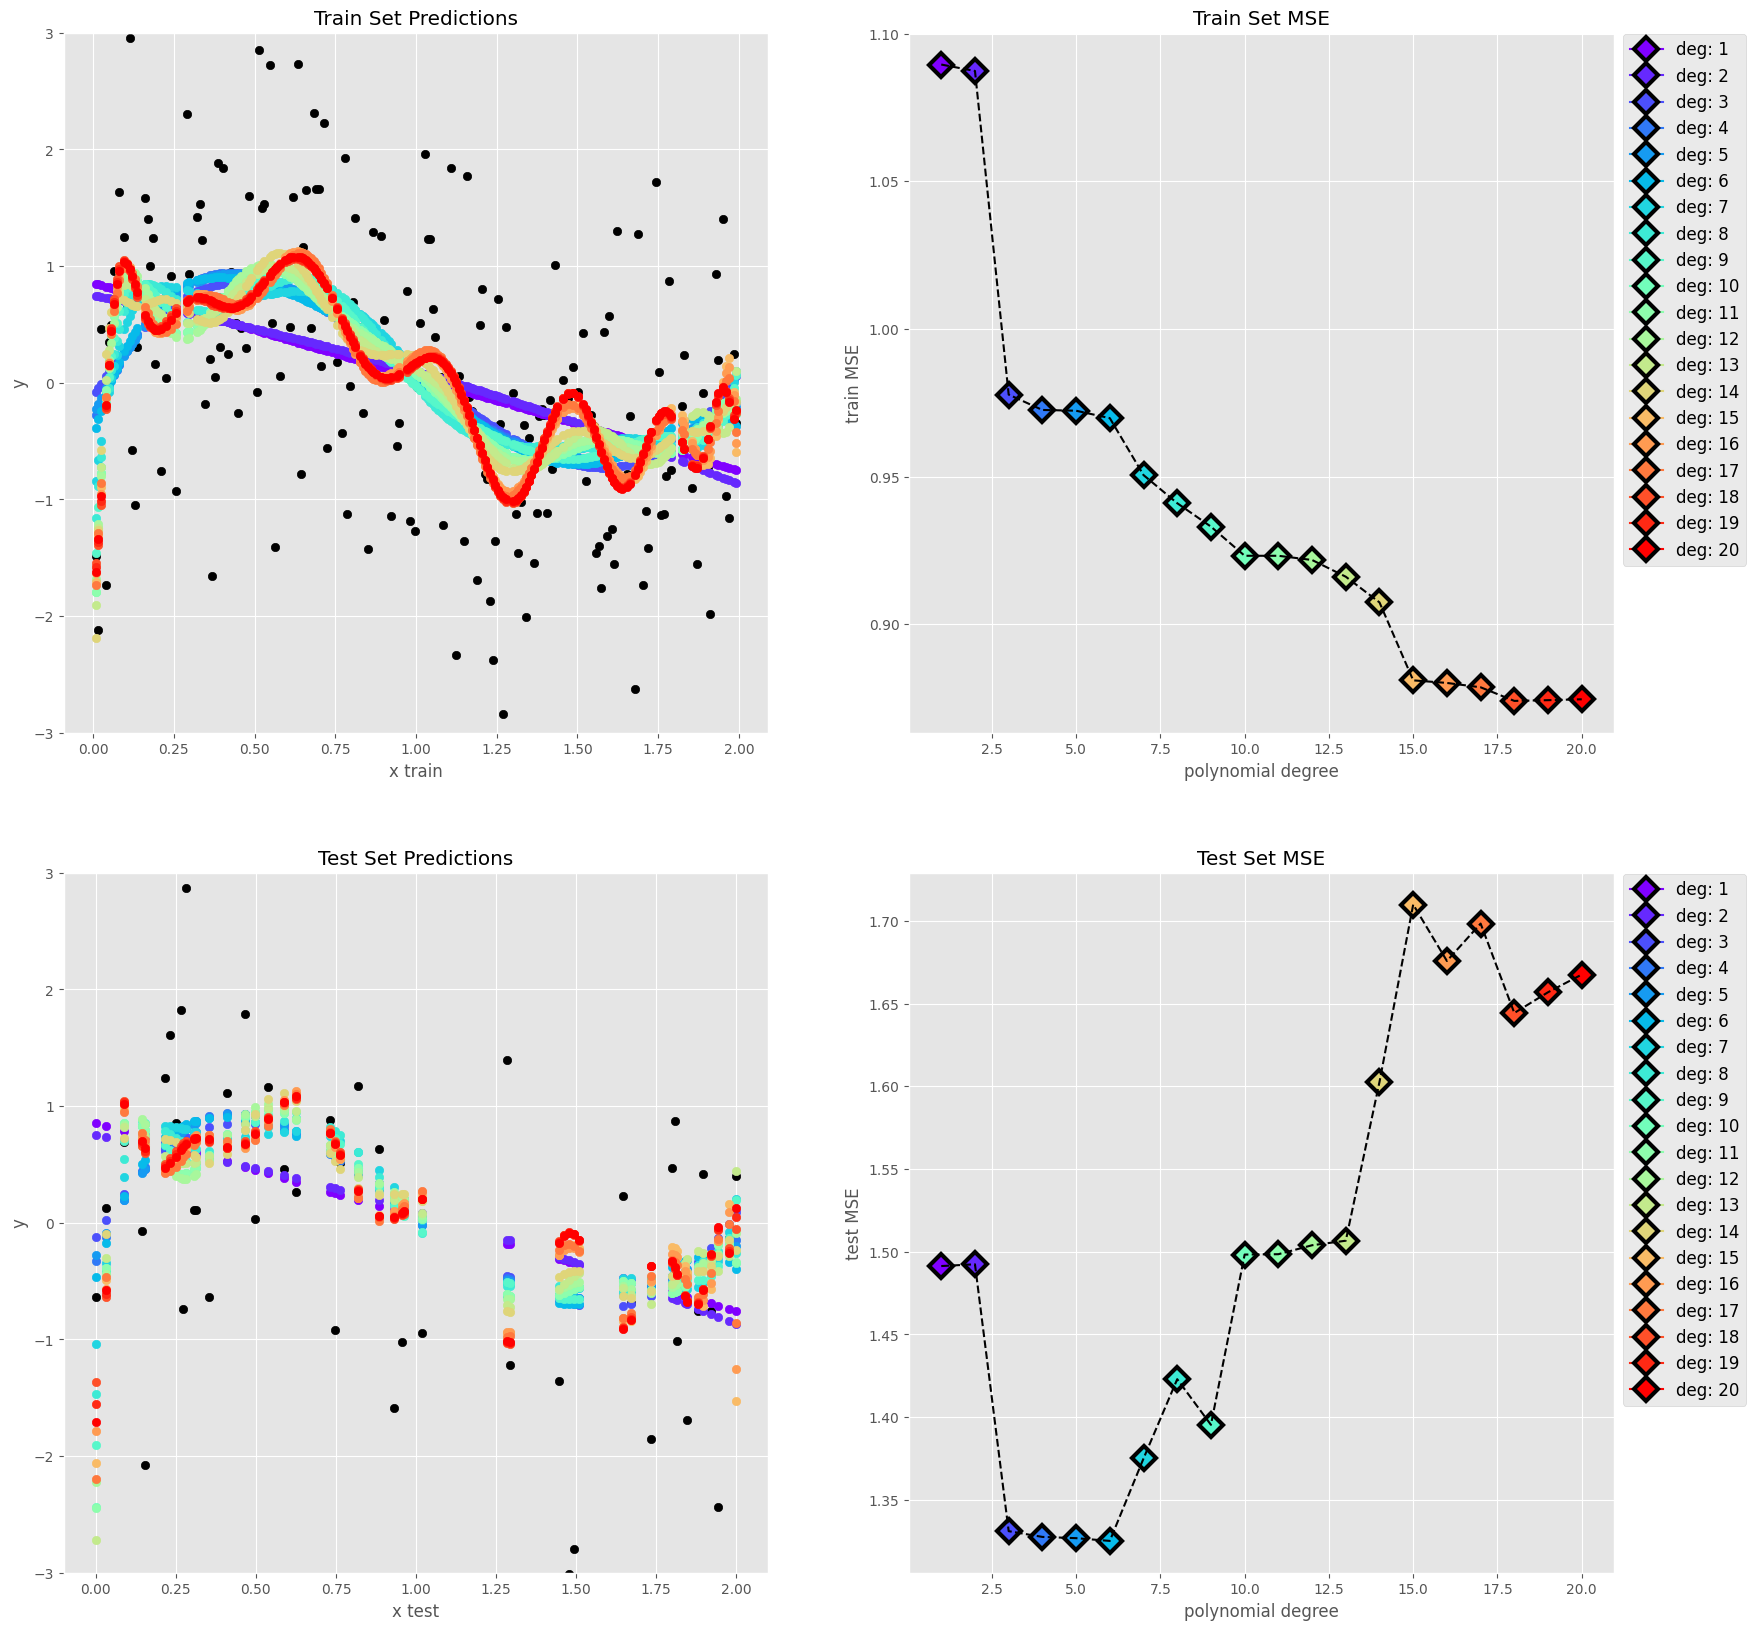

In [ ]:
# number of polynomial models to investigate
NUM_MODELS = 20

colors = iter(plt.cm.rainbow(np.linspace(0, 1, NUM_MODELS)))

fig, axs = plt.subplots(2, 2, figsize = (20,20))

axs[0, 0].set_title('Train Set Predictions')
axs[1, 0].set_title('Test Set Predictions')
axs[0, 1].set_title('Train Set MSE')
axs[1, 1].set_title('Test Set MSE')

axs[0, 0].set_xlabel("x train")
axs[0, 0].set_ylabel("y")
axs[0, 0].set_ylim([-3, 3])

axs[1, 0].set_xlabel("x test")
axs[1, 0].set_ylabel("y")
axs[1, 0].set_ylim([-3, 3])

axs[0, 1].set_xlabel("polynomial degree")
axs[0, 1].set_ylabel("train MSE")

axs[1, 1].set_xlabel("polynomial degree")
axs[1, 1].set_ylabel("test MSE")

axs[0,0].scatter(x_train, y_train, c = 'k', label = "y train")
axs[1,0].scatter(x_test, y_test, c = 'k', label = "y test")

train_mse = []
test_mse = []

for k in range(0, NUM_MODELS):
    c = next(colors)

    # k-th degree polynomial coefficients
    fit_coeff = np.polyfit(x_train, y_train, deg = k+1)

    # train and test k-th degree polynomial fit
    y_train_pred = np.polyval(fit_coeff, x_train)
    y_test_pred = np.polyval(fit_coeff, x_test)

    # plot train and test k-th degree polynomial fit

    axs[0,0].scatter(x_train,
                   y_train_pred,
                   color = c,
                   label = "deg: {}".format(k+1))

    axs[1,0].scatter(x_test,
                   y_test_pred,
                   color = c,
                   label = "deg: {}".format(k+1))


    # train and test MSE of k-th degree polynomial fit
    iter_train_mse = mean_squared_error(y_train_pred, y_train)
    iter_test_mse = mean_squared_error(y_test_pred, y_test)

    train_mse.append(iter_train_mse)
    test_mse.append(iter_test_mse)

    # plot train and test MSE of k-th degree polynomial fit

    axs[0,1].plot(k+1,
                iter_train_mse,
                color = c,
                label = "deg: {}".format(k+1),
                marker = 'D',
                markersize = 12,
                markeredgecolor = 'black',
                markeredgewidth = 3)

    axs[1,1].plot(k+1,
                iter_test_mse,
                color = c,
                label = "deg: {}".format(k+1),
                marker = 'D',
                markersize = 12,
                markeredgecolor = 'black',
                markeredgewidth = 3)


# plot dashed line to interpolate MSE measures
axs[0,1].plot(range(1,NUM_MODELS+1), train_mse, 'k--')
axs[1,1].plot(range(1,NUM_MODELS+1), test_mse, 'k--')

# draw legends
axs[0,1].legend(loc = "upper right", bbox_to_anchor = (1.2, 1.01), prop = {'size': 12})
axs[1,1].legend(loc = "upper right", bbox_to_anchor = (1.2, 1.01), prop = {'size': 12})

In [ ]:
print("Best fit polynomial degree: ", test_mse.index(min(test_mse)))

Best fit polynomial degree:  5


In [ ]:
from mlxtend.evaluate import bias_variance_decomp
from sklearn.tree import DecisionTreeRegressor
from mlxtend.data import boston_housing_data
from sklearn.model_selection import train_test_split


#X_train, X_test, y_train, y_test = train_test_split(x_train, y_train,
#                                                    test_size=0.3,
#                                                    random_state=123,
#                                                    shuffle=True)



tree_regressor = DecisionTreeRegressor(random_state=123)

avg_expected_loss, avg_bias, avg_var = bias_variance_decomp(
        tree_regressor, x_train.reshape(-1,1), y_train, x_test.reshape(-1,1), y_test,
        loss='mse',
        random_seed=123)

print('Average expected loss: %.3f' % avg_expected_loss)
print('Average bias: %.3f' % avg_bias)
print('Average variance: %.3f' % avg_var)

Average expected loss: 2.481
Average bias: 1.971
Average variance: 0.510


In [ ]:
tree_regressor.get_params()

{'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 123,
 'splitter': 'best'}

In [ ]:
from mlxtend.evaluate import bias_variance_decomp
from sklearn.tree import DecisionTreeRegressor
from mlxtend.data import boston_housing_data
from sklearn.model_selection import train_test_split


X, y = boston_housing_data()
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.3,
                                                    random_state=123,
                                                    shuffle=True)



tree_otro = DecisionTreeRegressor(random_state=123)

avg_expected_loss, avg_bias, avg_var = bias_variance_decomp(
        tree_otro, X_train, y_train, X_test, y_test,
        loss='mse',
        random_seed=123)

print('Average expected loss: %.3f' % avg_expected_loss)
print('Average bias: %.3f' % avg_bias)
print('Average variance: %.3f' % avg_var)

Average expected loss: 31.536
Average bias: 14.096
Average variance: 17.440


## Consigna 1: Ejemplo en regresión: ajustando polinomios a datos polinómicos

Para ver el compromiso **Bias-Variance** en la práctica, vamos a generar datos a partir de una
función que **nosotros conocemos**, y a ella le sumamos ruido aleatorio:

$$ y = f(x) + \varepsilon \qquad con \qquad f(x) = 0.5x^3 - 2x^2 + x + 3 \qquad y \qquad \varepsilon \sim N(0, \sigma^2) $$

- $f(x)$ es un **polinomio de grado 3**: es la "verdad" que el modelo no conoce.
- $\varepsilon$ es el **error irreducible** (ruido): ningún modelo puede predecirlo.

Después ajustaremos modelos polinómicos de **grado 1 a 15** y veremos qué pasa:

| Grado del modelo | Qué esperamos | Diagnóstico |
|---|---|---|
| 1 – 2 | Muy simple para una curva cúbica | **Underfitting** (alto bias) |
| 3 | Coincide con la función real | **Ajuste adecuado** |
| 10 – 15 | Demasiado flexible, aprende el ruido | **Overfitting** (alta varianza) |

> Como conocemos el grado verdadero (3), podemos comprobar si el análisis de error lo detecta.

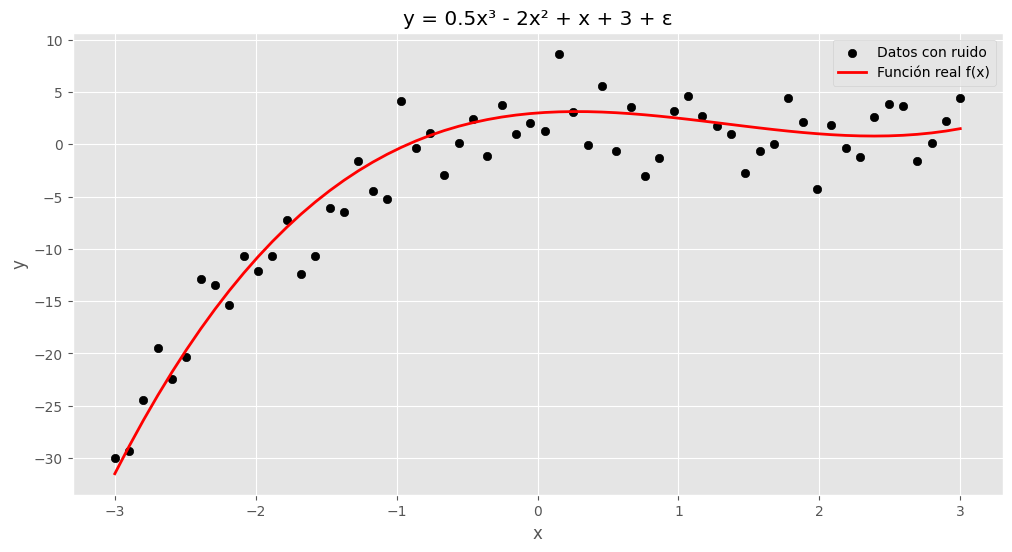

In [ ]:
import numpy as np                                      # operaciones numéricas y generación de datos aleatorios
import matplotlib.pyplot as plt                         # gráficos
from sklearn.metrics import mean_squared_error          # métrica de error: error cuadrático medio (MSE)
from sklearn.model_selection import train_test_split    # para separar datos de entrenamiento y de prueba
import warnings                                         # para controlar los avisos de Python

warnings.filterwarnings("ignore")   # polyfit avisa (RankWarning) con grados altos; lo silenciamos porque es esperable
plt.style.use('ggplot')             # estilo visual de los gráficos
np.random.seed(42)                  # fija la semilla: los resultados son reproducibles en cada ejecución

NUM_OBS = 60                        # cantidad de observaciones (pocas, para que el overfitting se note)
SIGMA = 3.0                         # desvío estándar del ruido (su cuadrado, SIGMA**2, es el error irreducible)

def f_verdadera(x):
    """Función real que genera los datos (polinomio de grado 3)."""
    return 0.5 * x**3 - 2 * x**2 + x + 3    # 0.5x³ - 2x² + x + 3

x = np.linspace(-3, 3, NUM_OBS)             # 60 valores de x equiespaciados entre -3 y 3
eps = np.random.normal(0, SIGMA, NUM_OBS)   # ruido gaussiano: media 0, desvío SIGMA
y = f_verdadera(x) + eps                    # variable objetivo = función real + ruido

fig = plt.figure(figsize=(12, 6))                       # crea la figura con tamaño 12x6 pulgadas
ax = plt.axes()                                         # crea los ejes
ax.set_title('y = 0.5x³ - 2x² + x + 3 + ε')             # título del gráfico
ax.set_xlabel("x")                                      # etiqueta del eje x
ax.set_ylabel("y")                                      # etiqueta del eje y
ax.scatter(x, y, c='k', label='Datos con ruido')        # puntos observados (lo que el modelo "ve")
ax.plot(x, f_verdadera(x), 'r-', lw=2, label='Función real f(x)')  # curva verdadera (lo que el modelo "debe descubrir")
ax.legend()                                             # muestra la leyenda
plt.show()                                              # dibuja el gráfico

### Separación en entrenamiento y prueba

Dividimos los datos en dos grupos:

- **Train (80%)**: el modelo aprende con estos datos.
- **Test (20%)**: datos que el modelo **nunca vio**; sirven para medir qué tan bien generaliza.

Un modelo que memoriza el set de entrenamiento tendrá un error de train muy bajo, pero un error
de test alto. Esa **brecha entre ambos errores** es la señal clásica de overfitting.

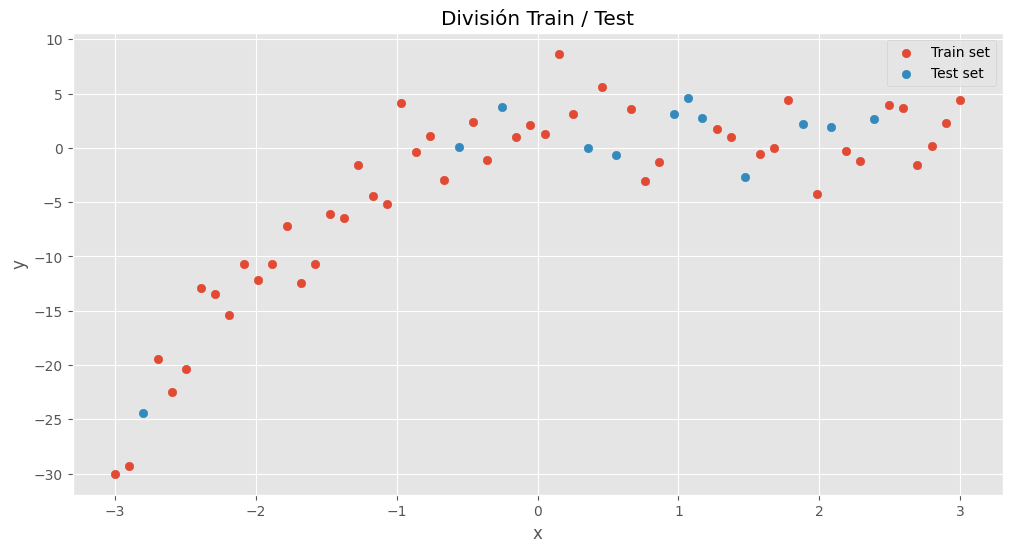

Observaciones de entrenamiento: 48 | de prueba: 12


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,                  # datos completos a dividir
    test_size=0.2,         # 20% para test, 80% para train
    random_state=1         # semilla para que la división sea siempre la misma
)

fig = plt.figure(figsize=(12, 6))                           # nueva figura
ax = plt.axes()                                             # ejes
ax.set_title('División Train / Test')                       # título
ax.set_xlabel("x")                                          # etiqueta eje x
ax.set_ylabel("y")                                          # etiqueta eje y
ax.scatter(x_train, y_train, label="Train set")             # puntos de entrenamiento
ax.scatter(x_test, y_test, label="Test set")                # puntos de prueba
ax.legend()                                                 # leyenda
plt.show()                                                  # muestra el gráfico
print(f"Observaciones de entrenamiento: {len(x_train)} | de prueba: {len(x_test)}")  # tamaño de cada conjunto

### Visualizando underfitting, ajuste adecuado y overfitting

Ajustamos tres polinomios con distinto grado y los comparamos contra la función real (línea roja):

- **Grado 1 (recta)**: demasiado simple, no captura la curvatura → *underfitting*.
- **Grado 3**: tiene la misma complejidad que la función real → buen ajuste.
- **Grado 15**: tan flexible que se "retuerce" para pasar cerca de cada punto de train,
  incluso del ruido → *overfitting*. Fijate cómo oscila, sobre todo en los extremos.

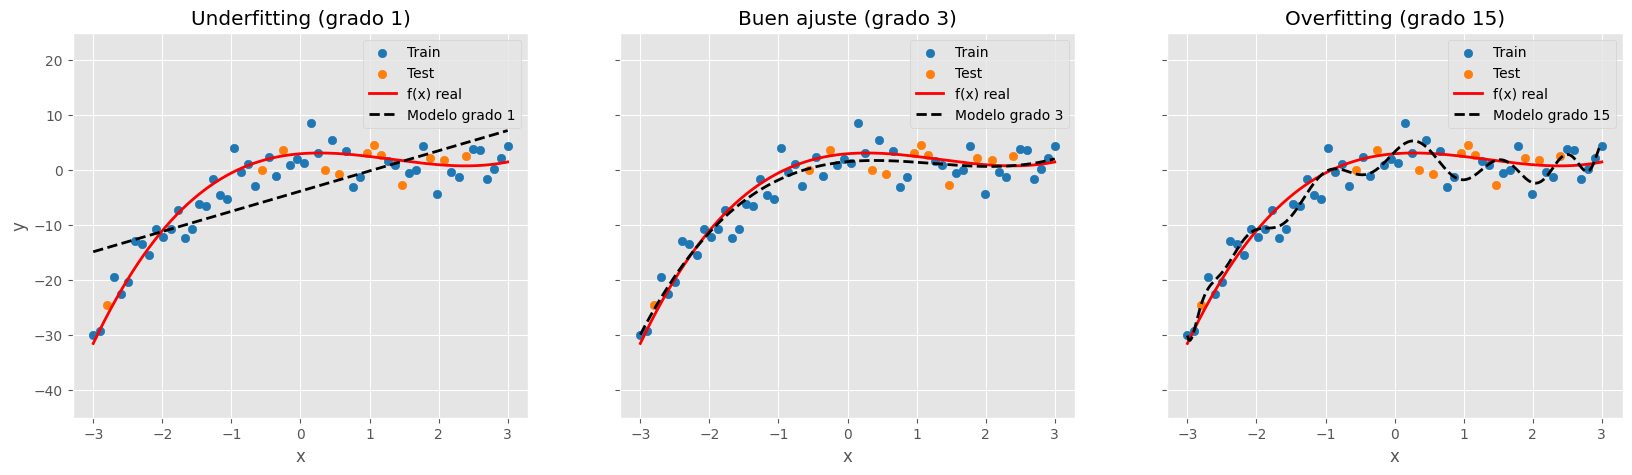

In [ ]:
grados_demo = [1, 3, 15]                                   # grados que vamos a mostrar
titulos = ['Underfitting (grado 1)', 'Buen ajuste (grado 3)', 'Overfitting (grado 15)']  # título de cada panel
x_plot = np.linspace(-3, 3, 300)                           # malla fina de x para dibujar curvas suaves

fig, axs = plt.subplots(1, 3, figsize=(20, 5), sharey=True)    # 3 gráficos en una fila, comparten eje y

for ax, g, t in zip(axs, grados_demo, titulos):            # recorre cada grado con su título y su eje
    coef = np.polyfit(x_train, y_train, deg=g)             # ajusta un polinomio de grado g SOLO con datos de train
    y_curva = np.polyval(coef, x_plot)                     # evalúa el polinomio ajustado en la malla fina

    ax.scatter(x_train, y_train, c='tab:blue', label='Train')   # puntos de entrenamiento
    ax.scatter(x_test, y_test, c='tab:orange', label='Test')    # puntos de prueba
    ax.plot(x_plot, f_verdadera(x_plot), 'r-', lw=2, label='f(x) real')   # función verdadera
    ax.plot(x_plot, y_curva, 'k--', lw=2, label=f'Modelo grado {g}')      # modelo ajustado
    ax.set_ylim(-45, 25)                                   # límites del eje y para que la curva no se salga del gráfico
    ax.set_title(t)                                        # título del panel
    ax.set_xlabel('x')                                     # etiqueta eje x
    ax.legend()                                            # leyenda

axs[0].set_ylabel('y')                                     # etiqueta del eje y solo en el primer panel
plt.show()                                                 # muestra los tres gráficos

### ¿Cuál es el mejor grado? Miremos el error en train y en test

Probamos **todos los grados de 1 a 15** y calculamos el **MSE** (error cuadrático medio) en ambos conjuntos.

- El **MSE de train** siempre baja al aumentar el grado: un modelo más flexible se ajusta mejor a lo que ya vio.
- El **MSE de test** baja hasta cierto punto y después **vuelve a subir**: ahí empieza el overfitting.

El mejor modelo es el que tiene **el menor error de test**.

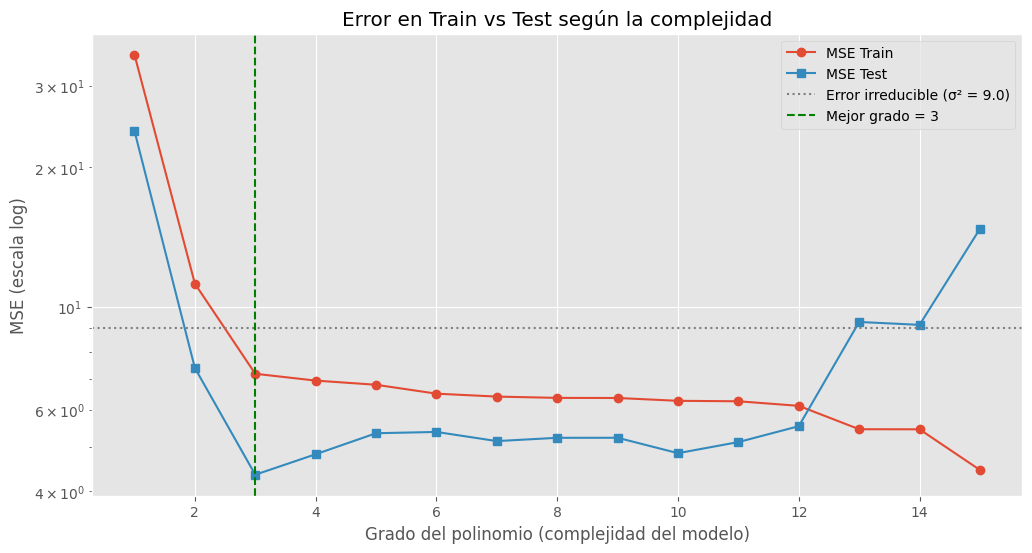

Mejor grado según el MSE de test: 3


In [ ]:
grados = range(1, 16)       # grados a evaluar: 1, 2, ..., 15
train_mse = []              # lista para guardar el error en train de cada grado
test_mse = []               # lista para guardar el error en test de cada grado

for g in grados:                                            # recorre cada grado
    coef = np.polyfit(x_train, y_train, deg=g)              # ajusta el polinomio con datos de train
    y_train_pred = np.polyval(coef, x_train)                # predicciones sobre train
    y_test_pred = np.polyval(coef, x_test)                  # predicciones sobre test (datos no vistos)
    train_mse.append(mean_squared_error(y_train, y_train_pred))  # guarda MSE de train
    test_mse.append(mean_squared_error(y_test, y_test_pred))     # guarda MSE de test

mejor_grado = list(grados)[int(np.argmin(test_mse))]        # grado con menor MSE de test (argmin da la posición; la convertimos en grado)

fig = plt.figure(figsize=(12, 6))                                           # nueva figura
plt.plot(grados, train_mse, 'o-', label='MSE Train')                        # curva del error de entrenamiento
plt.plot(grados, test_mse, 's-', label='MSE Test')                          # curva del error de prueba
plt.axhline(SIGMA**2, color='gray', ls=':', label=f'Error irreducible (σ² = {SIGMA**2:.1f})')  # piso teórico del error
plt.axvline(mejor_grado, color='green', ls='--', label=f'Mejor grado = {mejor_grado}')         # marca el mejor grado
plt.yscale('log')                                                           # escala log: el error explota con grados altos
plt.xlabel('Grado del polinomio (complejidad del modelo)')                  # eje x
plt.ylabel('MSE (escala log)')                                              # eje y
plt.title('Error en Train vs Test según la complejidad')                    # título
plt.legend()                                                                # leyenda
plt.show()                                                                  # muestra el gráfico

print("Mejor grado según el MSE de test:", mejor_grado)                     # imprime el grado óptimo (no el índice)

**¿Cómo leer este gráfico?**

- A la izquierda (grados 1-2), ambos errores son **altos**: el modelo es demasiado simple, hay **alto bias**.
- Cerca del grado 3, el error de test alcanza su mínimo y se acerca al **error irreducible** ($\sigma^2 = 9$).
  Es el punto de **complejidad óptima**.
- A la derecha, el error de train sigue bajando pero el de test **se dispara**. Esa brecha es la
  **alta varianza** (overfitting).

> Nota: al ser pocos datos y con ruido aleatorio, el mínimo puede caer en un grado cercano a 3 (por ejemplo 3, 4 o 5)
> y no exactamente en 3. Eso también es una lección: con pocos datos el ruido puede confundir la elección.

### Descomponiendo el error: Bias² + Varianza + Ruido

Hasta ahora usamos **una sola muestra** de datos. Para medir sesgo y varianza de verdad hay que
preguntarse: *¿qué pasaría si entrenara el mismo tipo de modelo con muchas muestras distintas?*

El procedimiento (lo que hace internamente `bias_variance_decomp` de mlxtend):

1. Generamos **200 conjuntos de entrenamiento distintos** (misma función, ruido distinto).
2. Para cada grado, ajustamos un modelo en cada conjunto y predecimos sobre una malla fija de $x$.
3. Calculamos:
   - **Bias²**: qué tan lejos está la **predicción promedio** de la función real $f(x)$.
   - **Varianza**: cuánto **cambian las predicciones** de un modelo a otro.
   - **Ruido**: $\sigma^2$, constante.

$$ Error\ esperado \approx Bias^2 + Varianza + \sigma^2 $$

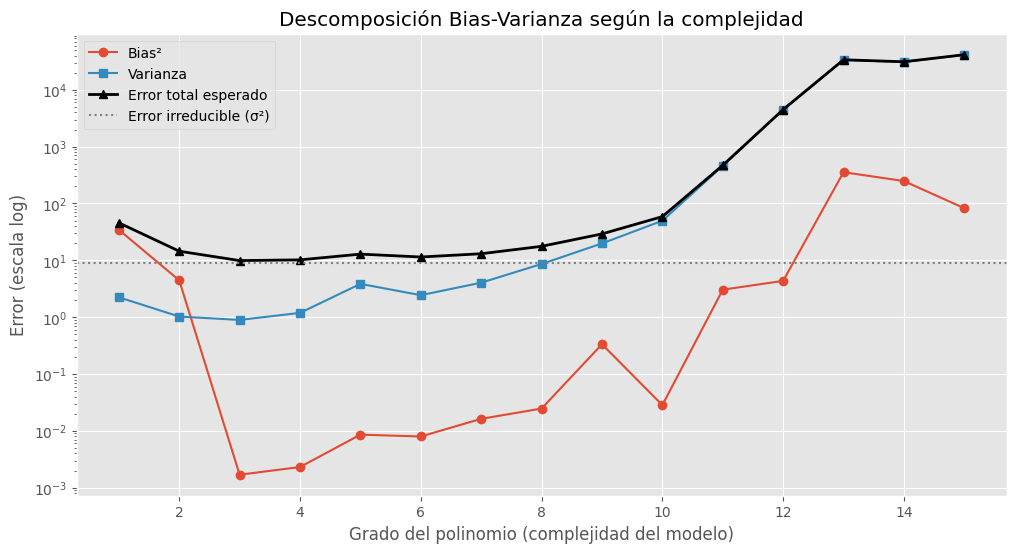

Grado con menor error total esperado: 3


In [ ]:
n_rep = 200                                  # cantidad de conjuntos de entrenamiento distintos a simular
n_train = 48                                 # tamaño de cada conjunto de entrenamiento
x_eval = np.linspace(-3, 3, 100)             # malla fija de puntos donde se compararán las predicciones
f_eval = f_verdadera(x_eval)                 # valor real de la función en esa malla
grados_bv = range(1, 16)                     # grados a evaluar

bias2_lista = []                             # aquí se guarda el bias² de cada grado
var_lista = []                               # aquí se guarda la varianza de cada grado

for g in grados_bv:                                          # recorre cada grado
    preds = np.empty((n_rep, len(x_eval)))                   # matriz: una fila de predicciones por cada repetición

    for r in range(n_rep):                                   # repite el experimento n_rep veces
        xs = np.random.uniform(-3, 3, n_train)               # nuevo conjunto de x aleatorios
        ys = f_verdadera(xs) + np.random.normal(0, SIGMA, n_train)  # nuevos y = f(x) + ruido distinto
        coef = np.polyfit(xs, ys, deg=g)                     # ajusta el polinomio de grado g a esta muestra
        preds[r, :] = np.polyval(coef, x_eval)               # guarda sus predicciones en la malla fija

    pred_media = preds.mean(axis=0)                          # predicción promedio de los 200 modelos en cada punto
    bias2 = np.mean((pred_media - f_eval) ** 2)              # bias²: distancia² entre predicción promedio y verdad
    varianza = np.mean(preds.var(axis=0))                    # varianza: dispersión de las predicciones entre modelos

    bias2_lista.append(bias2)                                # guarda bias² del grado g
    var_lista.append(varianza)                               # guarda varianza del grado g

bias2_arr = np.array(bias2_lista)                            # convierte a array para poder sumar
var_arr = np.array(var_lista)                                # idem
error_total = bias2_arr + var_arr + SIGMA**2                 # error esperado = bias² + varianza + ruido

plt.figure(figsize=(12, 6))                                              # nueva figura
plt.plot(grados_bv, bias2_arr, 'o-', label='Bias²')                      # curva de bias²
plt.plot(grados_bv, var_arr, 's-', label='Varianza')                     # curva de varianza
plt.plot(grados_bv, error_total, 'k^-', lw=2, label='Error total esperado')  # suma de los tres componentes
plt.axhline(SIGMA**2, color='gray', ls=':', label='Error irreducible (σ²)')   # piso del error
plt.yscale('log')                                                        # escala log por la explosión de la varianza
plt.xlabel('Grado del polinomio (complejidad del modelo)')               # eje x
plt.ylabel('Error (escala log)')                                         # eje y
plt.title('Descomposición Bias-Varianza según la complejidad')           # título
plt.legend()                                                             # leyenda
plt.show()                                                               # muestra el gráfico

print("Grado con menor error total esperado:", list(grados_bv)[int(np.argmin(error_total))])  # grado óptimo teórico

**Conclusiones del experimento**

- **Bias²** es enorme con grados 1 y 2 (modelo demasiado simple) y se vuelve casi **cero desde el grado 3**,
  porque el modelo ya tiene la forma de la función real.
- **Varianza** es muy baja con modelos simples y **crece rápidamente** con grados altos: cada muestra de
  entrenamiento produce un polinomio muy distinto.
- **Error total** tiene forma de "U": el mínimo se da donde Bias² y Varianza están **balanceados**
  (alrededor del grado 3). Ese es el **compromiso Bias-Variance**.
- El **error irreducible** ($\sigma^2$) es un piso: ni el mejor modelo puede bajar de ahí.

**Qué hacer en cada caso (conecta con la unidad de Evaluación y Validación):**

| Síntoma | Diagnóstico | Acción |
|---|---|---|
| Error alto en train y test | Alto bias | Aumentar complejidad, agregar variables polinómicas, reducir regularización |
| Error bajo en train, alto en test | Alta varianza | Simplificar, regularizar (Ridge/Lasso), conseguir más datos |

> **Idea clave:** en un caso real no conocemos la función verdadera, por eso en la práctica usamos
> **validación cruzada** y **curvas de aprendizaje** para encontrar ese punto óptimo.

## Ejemplo en clasificación

In [ ]:
!pip install --user mlxtend

In [ ]:
from mlxtend.evaluate import bias_variance_decomp
from sklearn.tree import DecisionTreeClassifier
from mlxtend.data import iris_data
from sklearn.model_selection import train_test_split


X, y = iris_data()
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.3,
                                                    random_state=123,
                                                    shuffle=True,
                                                    stratify=y)



tree = DecisionTreeClassifier(random_state=123)

avg_expected_loss, avg_bias, avg_var = bias_variance_decomp(
        tree, X_train, y_train, X_test, y_test,
        loss='0-1_loss',
        random_seed=123)

print('Average expected loss: %.3f' % avg_expected_loss)
print('Average bias: %.3f' % avg_bias)
print('Average variance: %.3f' % avg_var)

Average expected loss: 0.062
Average bias: 0.022
Average variance: 0.040


# Análisis del Error

## ¿Cómo tratamos el bias/variance?

## Hechos

> **Más datos** tiende a mejorar la performance de casi cualquier algoritmo.
> **Más características** también, siempre que sean de buena calidad.

Lo comprobamos con una **curva de aprendizaje**: medimos el error al crecer la cantidad de
datos de entrenamiento. Con pocos datos el modelo sobreajusta (gran brecha entre train y
validación); al aumentar los datos, ambas curvas convergen.

obviamente hablamos de datos y caraterísticas de buena calidad, en condiciones de ser procesadas por los algoritmos



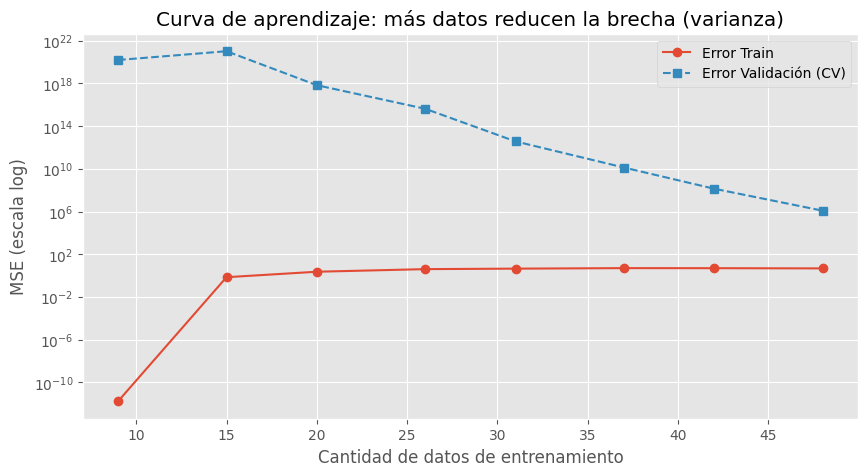

In [ ]:
from sklearn.model_selection import learning_curve                 # calcula el error según el tamaño del set de entrenamiento
from sklearn.pipeline import make_pipeline                         # encadena pasos de preprocesamiento + modelo
from sklearn.preprocessing import PolynomialFeatures               # genera las columnas x, x², x³, ...
from sklearn.linear_model import LinearRegression                  # regresión lineal sobre esas columnas

# Aseguramos el uso de los datos de regresión correctos y consistentes
x_reg_curve = np.linspace(-3, 3, NUM_OBS)
eps_reg_curve = np.random.normal(0, SIGMA, NUM_OBS)
y_reg_curve = f_verdadera(x_reg_curve) + eps_reg_curve

modelo = make_pipeline(PolynomialFeatures(degree=10), LinearRegression())   # modelo flexible (grado 10) para ver el overfitting

tamanios, train_sc, val_sc = learning_curve(
    modelo,                                    # modelo a evaluar
    x_reg_curve.reshape(-1, 1), y_reg_curve,   # usando los datos de regresión consistentes
    train_sizes=np.linspace(0.2, 1.0, 8),      # usa del 20% al 100% de los datos en 8 pasos
    cv=5,                                      # validación cruzada de 5 particiones
    scoring='neg_mean_squared_error'           # métrica: MSE (sklearn lo devuelve en negativo)
)

plt.figure(figsize=(10, 5))                                              # nueva figura
plt.plot(tamanios, -train_sc.mean(axis=1), 'o-', label='Error Train')    # signo menos para volver a MSE positivo
plt.plot(tamanios, -val_sc.mean(axis=1), 's--', label='Error Validación (CV)')  # error en datos no vistos
plt.yscale('log')                                                        # escala log porque la brecha es muy grande
plt.xlabel('Cantidad de datos de entrenamiento')                         # eje x
plt.ylabel('MSE (escala log)')                                           # eje y
plt.title('Curva de aprendizaje: más datos reducen la brecha (varianza)')  # título
plt.legend()                                                             # leyenda
plt.show()                                                               #

### Enfoque recomendado


1- Iniciar con un modelo simple, rápido de implementar.

2- Agregar un set para hacer cross validation y testear de ésta forma. Esto implica implementar métodos de Resampling, Emsebling, Boosting, Bagging.

3- Dibijar la curva de aprendizaje para determinar si se necesitan mas datos, mas características, etc.
Repasando: mas datos debería disminuir el bias, mas características debería disminuir la varianza.

4- Analizar el error.

## Posibles tratamientos con bias y varianza alta



|High Bias |	High Varianza |
| :--| :-- |
|intentar obtener caractedísticas adicionales| obtener mas datos de entrenamiento|
| 	 intentar agregar características polinomiales| 	intentar con un conjunto de características mas pequeño - Reducción dimencional|
|achicar $\lambda$ (lambda: coeficiente de regularización) | 	agrandar $\lambda$ (lambda: coeficiente de regularización)|




## Referencias

https://www.kaggle.com/code/residentmario/bias-variance-tradeoff/notebook


http://scott.fortmann-roe.com/docs/BiasVariance.html





#Consignas Actividad a entregar:

Tomar el código del colab:

https://colab.research.google.com/drive/14UnWuDyzVXWFG7k6Av5wstKEHHDYDQyq#scrollTo=X09UT67AmW37


1- modificar la función original de sin() a otra a su criterio

2- En el algoritmo polyfit() analizar y agragar la función bias_variace_decom() para evaluar ambos errores.

3- En la celda de DecisionTreeRegressor() evaluar una mejora para llevar el error al mínimo posible de bias y varianza.

4- Aplicar validación cruzada. Compara entre GridSearchCV y RandomizedSearchCV

5- Agregar ejercicios de la Unidad 6:
https://docs.google.com/document/d/13g9m6SDih0lCzxeF9qnK-yzgbX_pJueW5FXwlUlNpok/edit?tab=t.0

Fecha de entrega: 09/11/26

---
#Consignas pendientes y su resolución:

> Las secciones siguientes se agregan **después de "Referencias"** y resuelven lo que faltaba de las *"Modificaciones según actividades de clase"*.
> Cada sección es **autocontenida**: define sus propios datos y variables (`x_p`, `Xp_tr`, `Xb_tr`, etc.) para no chocar con las variables que se sobrescriben en las secciones anteriores (por ejemplo `x`, `x_train`, `NUM_OBS`, `SIGMA`).

##Checklist de consignas

| # | Consigna | Estado | Dónde está resuelta |
|---|---|---|---|
| 1 | Modificar la función original `sin()` por otra | ✅ **Resuelta (en clase)** | Sección **"Consigna 1: Ejemplo en regresión: ajustando polinomios a datos polinómicos"** y sus subtítulos: *Separación en entrenamiento y prueba*, *Visualizando underfitting, ajuste adecuado y overfitting*, *¿Cuál es el mejor grado?*, *Descomponiendo el error: Bias² + Varianza + Ruido* y *Conclusiones del experimento*. |
| 2 | `polyfit()` + `bias_variance_decomp()` | 🟡 **Parcial → completada ahora** | **Ya estaba:** la descomposición hecha *a mano* (sección *Descomponiendo el error*) y `bias_variance_decomp` aplicada solo a `DecisionTreeRegressor` / `DecisionTreeClassifier` (secciones *Ejemplo en regresión lineal* y *Ejemplo en clasificación*). **Faltaba:** aplicarla a los modelos polinómicos de `polyfit`. → **Sección Consigna 2 (abajo)**. |
| 3 | Mejorar el `DecisionTreeRegressor()` para minimizar Bias y Varianza | ⬜ **Pendiente → resuelta ahora** | Antes solo existía el árbol con parámetros por defecto. → **Sección Consigna 3 (abajo)**. |
| 4 | Validación cruzada: `GridSearchCV` vs `RandomizedSearchCV` | ⬜ **Pendiente → resuelta ahora** | En *Hechos* ya había un `learning_curve(cv=5)`, pero solo como diagnóstico, sin comparar buscadores. → **Sección Consigna 4 (abajo)**. |
| 5 | Ejercicios de la Unidad 6 (Actividades 1, 2 y 3) | ⬜ **Pendiente → resueltas ahora** | → **Sección Consigna 5 (abajo)**. |
| TP | Trabajo Práctico comparativo (3 modelos, Pipelines, Learning Curves) | ⬜ **Pendiente → resuelto ahora** | → **Sección 6.0 Trabajo Practico (abajo)**. |
| — | *"Lo que falta: técnicas de regularización"* (nota de la sección *Lo que falta*) | 🟡 **Cubierto en parte** | Regularización **L2 (Ridge)** en la Sección 4 y **Regresión Logística L2** en la Sección 6. |

**¿Cómo ejecutar las actividades de esta segunda parte?**

Correr primero la celda de *Configuración común* y luego las secciones en orden. La Sección 4 reutiliza los datos creados en la Sección 2.


###Configuración común
Importamos las librerías que usarán todas las secciones nuevas y fijamos una **semilla global** (`SEED = 42`) para que los resultados sean reproducibles.

In [ ]:
# Instalamos mlxtend y xgboost solo si no están disponibles (en Colab ya vienen preinstaladas)
import sys, subprocess
try:
    import mlxtend, xgboost
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'mlxtend', 'xgboost'])

import time                                           # para medir tiempos de cómputo
import warnings                                       # para controlar avisos
import numpy as np                                    # cálculo numérico
import pandas as pd                                   # tablas de resultados
import matplotlib.pyplot as plt                       # gráficos

from sklearn.pipeline import Pipeline, make_pipeline            # encadena pasos (preproceso + modelo)
from sklearn.preprocessing import PolynomialFeatures, StandardScaler   # features polinómicas y escalado
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression  # modelos lineales
from sklearn.model_selection import train_test_split            # partición train / test
from sklearn.metrics import mean_squared_error                  # métrica de regresión
from mlxtend.evaluate import bias_variance_decomp               # función de la consigna 2

warnings.filterwarnings("ignore")     # silenciamos avisos esperables (p. ej. grados altos en polinomios)
plt.style.use('ggplot')               # estilo de los gráficos
SEED = 42                             # semilla global para que todo sea reproducible
print("Librerías cargadas correctamente")

Librerías cargadas correctamente


---
## Consigna 2 · `polyfit()` + `bias_variance_decomp()` de mlxtend

**Idea.** Ya calculamos Bias² y Varianza *a mano* repitiendo el experimento con 200 muestras nuevas. La librería **mlxtend** ofrece `bias_variance_decomp()`, que hace lo mismo de forma automática con **bootstrap**:

1. Toma el set de entrenamiento y genera `num_rounds` muestras *con reposición*.
2. Entrena el modelo en cada muestra y predice sobre el set de **test**.
3. Calcula:
   - **Bias²** = distancia² entre la **predicción promedio** y el valor observado `y`.
   - **Varianza** = cuánto **cambian** las predicciones de una muestra a otra.
   - **Error esperado** = Bias² + Varianza (para `loss='mse'`).

**Problema:** `np.polyfit()` **no es un estimador de sklearn** (no tiene `fit()`/`predict()`), así que no se le puede pasar a `bias_variance_decomp`.
**Solución:** usar `Pipeline(PolynomialFeatures + LinearRegression)`, que resuelve *exactamente el mismo problema de mínimos cuadrados* (lo verificamos en la primera celda).

> ⚠️ **Detalle importante:** `bias_variance_decomp` compara contra el `y` **observado** (que ya trae ruido). Por eso el "Bias²" que devuelve es en realidad *Bias² verdadero + ruido*. En el paso 3 lo comprobamos calculando el bias contra la función **real** `f(x)`, algo que solo podemos hacer porque en este ejemplo *conocemos* la verdad.

In [ ]:
# ---------- Datos: mismo modelo polinómico de la sección anterior, pero con variables propias ----------
def f_cubica(x):
    """Función verdadera (polinomio de grado 3) que genera los datos."""
    return 0.5 * x**3 - 2 * x**2 + x + 3

SIGMA_P = 3.0                                         # desvío del ruido -> error irreducible = SIGMA_P**2 = 9
N_P = 100                                             # cantidad de observaciones
rng = np.random.default_rng(SEED)                     # generador aleatorio con semilla

x_p = np.linspace(-3, 3, N_P)                         # x equiespaciado entre -3 y 3
y_p = f_cubica(x_p) + rng.normal(0, SIGMA_P, N_P)     # y = f(x) + ruido gaussiano

X_p = x_p.reshape(-1, 1)                              # sklearn exige X en 2D (n_muestras, n_variables)
Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(        # 80% train / 20% test
    X_p, y_p, test_size=0.2, random_state=1)

# ---------- Paso 1: ¿polyfit y un Pipeline de sklearn son lo mismo? ----------
g = 3                                                                  # probamos con grado 3
coef = np.polyfit(Xp_tr.ravel(), yp_tr, deg=g)                         # ajuste con polyfit (mínimos cuadrados)
pred_polyfit = np.polyval(coef, Xp_te.ravel())                         # predicciones de polyfit en test

modelo_sk = make_pipeline(                                             # mismo modelo, versión sklearn:
    PolynomialFeatures(degree=g, include_bias=False),                  #   1) crea las columnas x, x², x³
    LinearRegression())                                                #   2) regresión lineal por mínimos cuadrados
modelo_sk.fit(Xp_tr, yp_tr)                                            # entrena con los datos de train
pred_sklearn = modelo_sk.predict(Xp_te)                                # predicciones en test

print("¿Predicciones idénticas?:", np.allclose(pred_polyfit, pred_sklearn))   # True => son equivalentes

¿Predicciones idénticas?: True


σ² teórico = 9.00  |  ruido realizado en test = 4.18


,bias_mlxtend,varianza,error_total,bias_polyfit_manual,bias2_real,varianza_manual,bias2_real + ruido_test
grado,,,,,,,
1,27.11,1.13,28.25,27.11,25.39,1.13,29.56
2,5.36,0.33,5.68,5.36,2.82,0.33,6.99
3,4.67,0.21,4.88,4.67,0.51,0.21,4.68
4,4.66,0.26,4.92,4.66,0.36,0.26,4.53
5,5.16,0.30,5.46,5.16,0.44,0.30,4.62
6,5.17,0.35,5.51,5.17,0.46,0.35,4.64
7,5.18,0.42,5.60,5.18,0.48,0.42,4.65
8,5.49,0.49,5.98,5.49,0.58,0.49,4.76
9,5.71,0.54,6.25,5.71,0.63,0.54,4.81



Grado con menor error esperado (mlxtend): 3


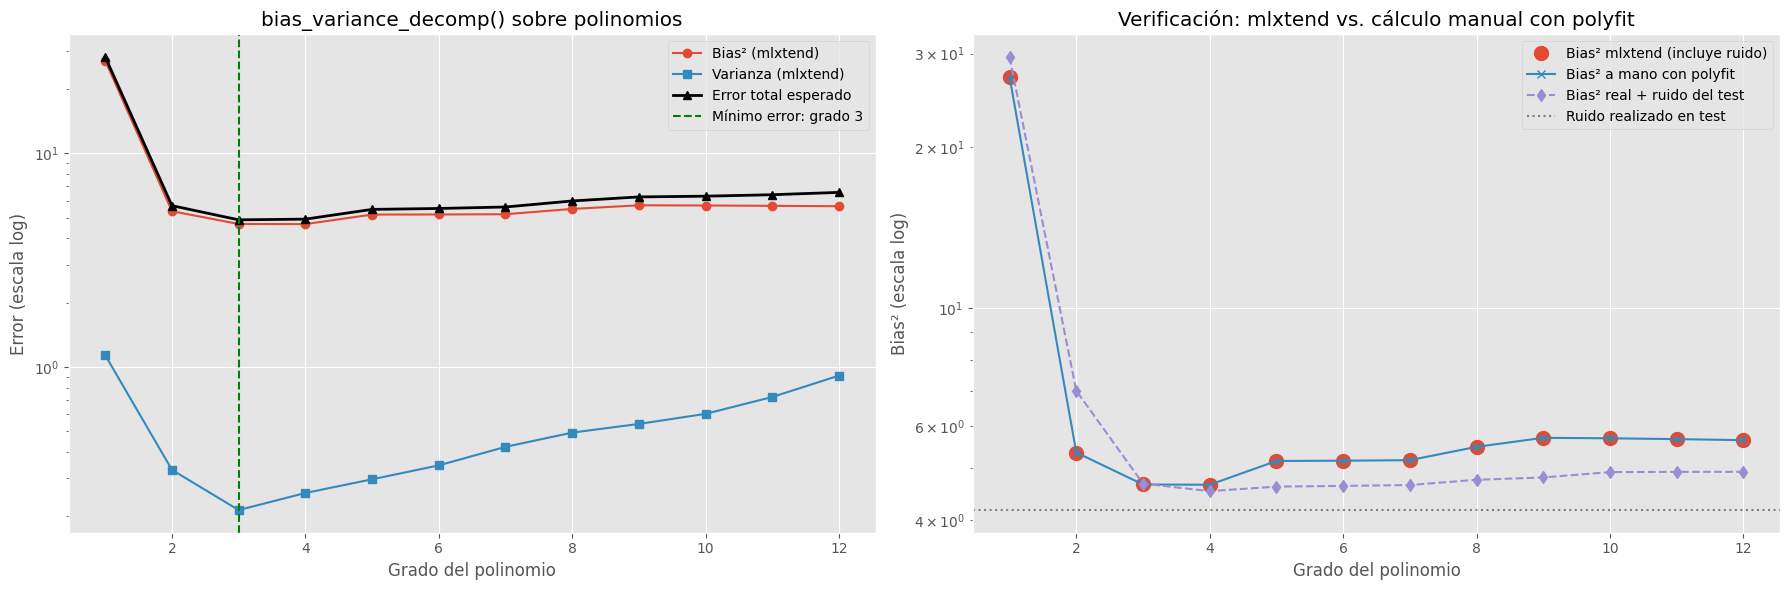

In [ ]:
# ---------- Paso 2: descomposición Bias-Varianza con mlxtend para cada grado ----------
grados_bv = range(1, 13)                  # grados 1 a 12 (con 13-15 la inestabilidad numérica distorsiona la escala)
filas = []                                # aquí acumulamos los resultados

for g in grados_bv:                                                        # recorre cada grado
    modelo = make_pipeline(PolynomialFeatures(g, include_bias=False),      # equivalente a np.polyfit(deg=g)
                           LinearRegression())
    loss, bias, var = bias_variance_decomp(                                # función pedida en la consigna
        modelo,                                                            # estimador con fit/predict
        Xp_tr, yp_tr, Xp_te, yp_te,                                        # datos de train y de test
        loss='mse',                                                        # error cuadrático medio
        num_rounds=200,                                                    # 200 re-muestreos bootstrap del train
        random_seed=SEED)                                                  # reproducibilidad
    filas.append({'grado': g, 'bias_mlxtend': bias, 'varianza': var, 'error_total': loss})

res_mlx = pd.DataFrame(filas).set_index('grado')                           # tabla con índice = grado

# ---------- Paso 3: la misma idea "a mano" con np.polyfit, y contra la función REAL ----------
def bias_var_polyfit(g, n_rounds=200, seed=SEED):
    """Replica por dentro lo que hace mlxtend, usando np.polyfit en lugar de sklearn."""
    r = np.random.RandomState(seed)                                        # generador de números aleatorios
    preds = np.empty((n_rounds, len(Xp_te)))                               # una fila de predicciones por re-muestreo
    for i in range(n_rounds):                                              # repite el experimento
        idx = r.randint(0, len(Xp_tr), len(Xp_tr))                         # bootstrap: muestreo CON reposición
        c = np.polyfit(Xp_tr.ravel()[idx], yp_tr[idx], deg=g)              # ajusta polyfit a la muestra bootstrap
        preds[i] = np.polyval(c, Xp_te.ravel())                            # predice en los puntos de test
    pred_media = preds.mean(axis=0)                                        # predicción promedio de los modelos
    bias_obs = np.mean((pred_media - yp_te) ** 2)                          # bias² contra el y OBSERVADO (incluye ruido)
    bias_real = np.mean((pred_media - f_cubica(Xp_te.ravel())) ** 2)       # bias² contra la función REAL (sin ruido)
    varianza = np.mean(preds.var(axis=0))                                  # varianza entre modelos
    return bias_obs, bias_real, varianza

manual = np.array([bias_var_polyfit(g) for g in grados_bv])                # calcula para todos los grados
res_mlx['bias_polyfit_manual'] = manual[:, 0]                              # bias² (con ruido) hecho a mano
res_mlx['bias2_real'] = manual[:, 1]                                       # bias² puro (sin ruido)
res_mlx['varianza_manual'] = manual[:, 2]                                  # varianza hecha a mano
ruido_test = np.mean((yp_te - f_cubica(Xp_te.ravel())) ** 2)               # ruido REALIZADO en los 20 puntos de test (≈ σ², pero con variación muestral)
res_mlx['bias2_real + ruido_test'] = res_mlx['bias2_real'] + ruido_test    # relación teórica: bias_mlxtend ≈ bias²_real + ruido del test
print(f"σ² teórico = {SIGMA_P**2:.2f}  |  ruido realizado en test = {ruido_test:.2f}")

pd.options.display.float_format = '{:,.2f}'.format                         # formato de números
display(res_mlx)

mejor = res_mlx['error_total'].idxmin()                                    # grado con menor error total esperado
print(f"\nGrado con menor error esperado (mlxtend): {mejor}")

# ---------- Gráficos ----------
fig, axs = plt.subplots(1, 2, figsize=(18, 6))

axs[0].plot(res_mlx.index, res_mlx['bias_mlxtend'], 'o-', label='Bias² (mlxtend)')          # bias de mlxtend
axs[0].plot(res_mlx.index, res_mlx['varianza'], 's-', label='Varianza (mlxtend)')            # varianza de mlxtend
axs[0].plot(res_mlx.index, res_mlx['error_total'], 'k^-', lw=2, label='Error total esperado')# suma de ambos
axs[0].axvline(mejor, color='green', ls='--', label=f'Mínimo error: grado {mejor}')          # grado óptimo
axs[0].set_yscale('log'); axs[0].set_xlabel('Grado del polinomio'); axs[0].set_ylabel('Error (escala log)')
axs[0].set_title('bias_variance_decomp() sobre polinomios'); axs[0].legend()

axs[1].plot(res_mlx.index, res_mlx['bias_mlxtend'], 'o', ms=10, label='Bias² mlxtend (incluye ruido)')   # puntos mlxtend
axs[1].plot(res_mlx.index, res_mlx['bias_polyfit_manual'], 'x-', label='Bias² a mano con polyfit')       # a mano
axs[1].plot(res_mlx.index, res_mlx['bias2_real + ruido_test'], 'd--', label='Bias² real + ruido del test')  # teoría
axs[1].axhline(ruido_test, color='gray', ls=':', label='Ruido realizado en test')                        # piso
axs[1].set_yscale('log'); axs[1].set_xlabel('Grado del polinomio'); axs[1].set_ylabel('Bias² (escala log)')
axs[1].set_title('Verificación: mlxtend vs. cálculo manual con polyfit'); axs[1].legend()
plt.tight_layout(); plt.show()

**Interpretación**

- **Grado 1:** Bias² ≈ 27 y es la causa casi total del error → **underfitting**: una recta no puede describir una curva cúbica.
- **Grado 3:** el error esperado es **mínimo (≈ 4,9)**. El Bias² cae a ≈ 4,7 y la Varianza es la más baja (≈ 0,2). Coincide con el grado real de la función generadora.
- **Grados 4 a 12:** el Bias² ya no mejora, pero la **Varianza crece de ≈ 0,2 a ≈ 0,9** (se **cuadruplica**) → empieza el **overfitting**.
- **El piso no es cero:** el Bias² de mlxtend nunca baja de ≈ 4,7 porque incluye el **ruido** del test (≈ 4,2 en nuestros 20 puntos de test). El bias *real* (columna `bias2_real`) sí llega a ≈ 0,4–0,5.
- **Verificación (gráfico derecho):** el cálculo manual con `np.polyfit` **coincide con mlxtend** y la relación *Bias² mlxtend ≈ Bias² real + ruido del test* se cumple cerca del grado 3 (con grados altos se separa un poco por el término cruzado entre el error del modelo y el ruido).

> **Conclusión de la consigna:** `polyfit` + `bias_variance_decomp` confirma, con una herramienta estándar, lo que mostraba el gráfico de MSE train/test: la complejidad óptima está en **grado 3**.

---
## Consigna 3 · Mejorar el `DecisionTreeRegressor()` hacia el mínimo Bias y Varianza

**Diagnóstico del punto de partida.** Un árbol con parámetros por defecto crece hasta que cada hoja tiene una sola muestra: **memoriza el ruido** → **varianza muy alta** (con Bias² moderado). Para bajar el error esperado hay que atacar cada componente con la herramienta adecuada:

| Paso | Técnica | Componente que ataca | Cómo funciona |
|---|---|---|---|
| 0 | Árbol por defecto | — (línea base) | Sin restricciones |
| 1 | **Poda** con `GridSearchCV` | ↓ Varianza (a costa de algo de Bias) | Limita `max_depth` y `min_samples_leaf`, eligiendo con validación cruzada |
| 2 | **Bagging** | ↓ Varianza | Promedia 100 árboles entrenados en muestras *bootstrap* |
| 3 | **Random Forest** | ↓↓ Varianza | Bagging + cada división considera solo un subconjunto aleatorio de variables → árboles menos correlacionados |
| 4 | **Gradient Boosting** | ↓ Bias | Árboles poco profundos *en secuencia*; cada uno corrige el error del anterior |

Evaluamos **todo con `bias_variance_decomp`** (misma semilla y mismos datos) sobre **dos datasets**: el de **Boston Housing** (el de la celda original) y el de **`y = sin(πx) + ruido`** (el de la sección *Ejemplo en regresión lineal*).

> **¿Cuál es el "mínimo posible"?** En datos reales no se conoce el ruido irreducible, así que el mínimo se define como **el menor error esperado alcanzado**. En el dataset del seno sí lo conocemos: σ² = 1 (ruido `N(0,1)`), por lo que **ningún modelo puede bajar de 1,0**.

[Boston] Mejor árbol podado: {'max_depth': 8, 'min_samples_leaf': 3}
[Boston] Mejor Random Forest: {'max_features': 0.5, 'min_samples_leaf': 1}
[Boston] Mejor Gradient Boosting: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 300}
[Seno] Mejor árbol podado: {'max_depth': 2, 'min_samples_leaf': 12}
[Seno] Mejor Random Forest: {'max_features': 0.5, 'min_samples_leaf': 5}
[Seno] Mejor Gradient Boosting: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 100}

Tiempo total: 148 s

=== Boston Housing ===


,Error esperado,Bias²,Varianza,Mejora vs. base (%)
0) Árbol por defecto,37.057,16.486,20.571,0.000
1) Árbol podado (CV),31.666,18.025,13.641,14.546
2) Bagging (100 árboles),18.795,15.626,3.169,49.281
3) Random Forest (CV),15.508,13.732,1.777,58.149
4) Gradient Boosting (CV),15.481,12.764,2.717,58.223


=== y = sin(πx) + ruido ===


,Error esperado,Bias²,Varianza,Mejora vs. base (%)
0) Árbol por defecto,1.922,1.411,0.511,0.000
1) Árbol podado (CV),1.079,1.004,0.075,43.873
2) Bagging (100 árboles),1.525,1.227,0.298,20.659
3) Random Forest (CV),1.139,1.029,0.111,40.712
4) Gradient Boosting (CV),1.036,0.980,0.057,46.064


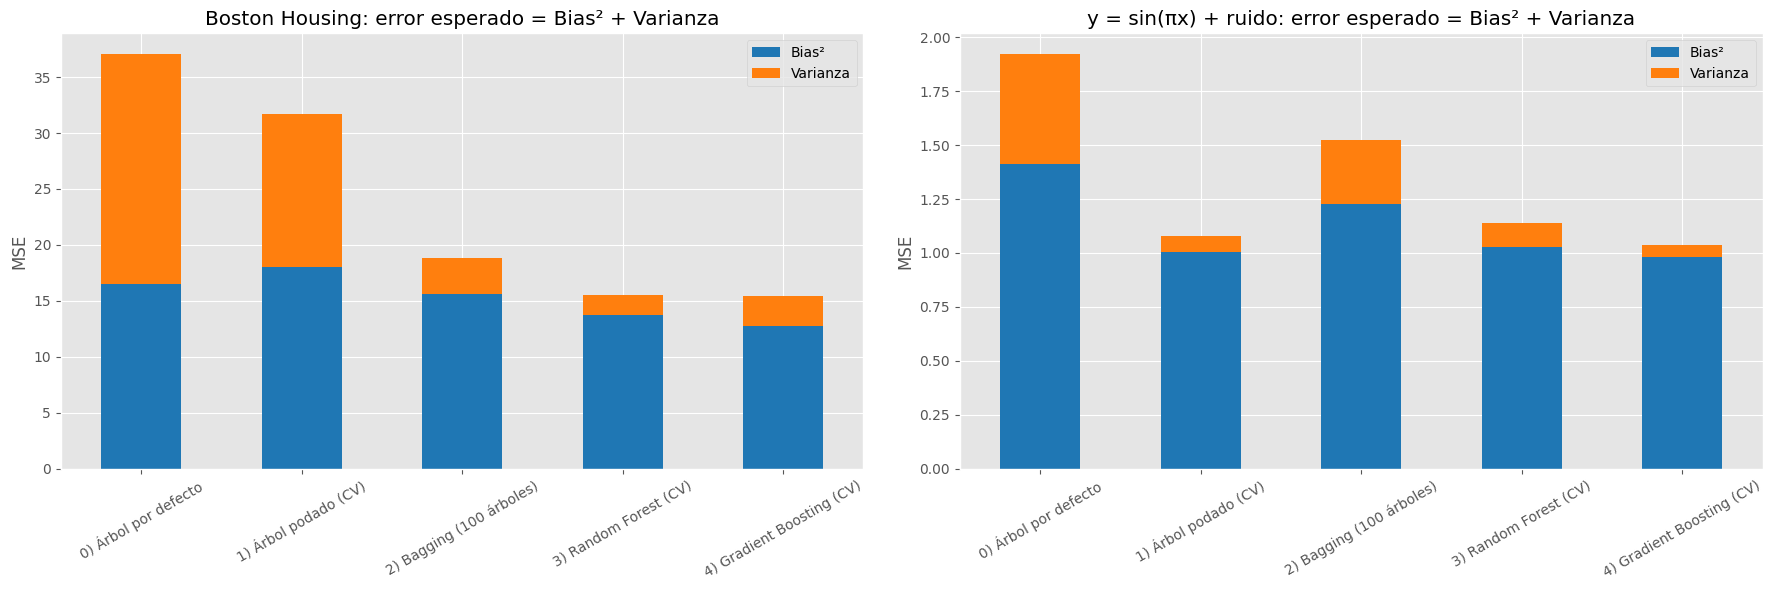

In [ ]:
from mlxtend.data import boston_housing_data                              # dataset real usado en la celda original
from sklearn.tree import DecisionTreeRegressor                            # modelo base de la consigna
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, KFold                   # búsqueda de hiperparámetros con CV

def decomp(modelo, Xtr, ytr, Xte, yte, rounds=50):
    """Descomposición Bias-Varianza de un modelo (mismos datos y semilla para comparar justo)."""
    loss, b, v = bias_variance_decomp(modelo, Xtr, ytr, Xte, yte,
                                      loss='mse', num_rounds=rounds, random_seed=SEED)
    return {'Error esperado': loss, 'Bias²': b, 'Varianza': v}

def comparar_modelos(nombre, Xtr, ytr, Xte, yte):
    """Evalúa árbol base y 4 mejoras; devuelve una tabla con Bias², Varianza y Error esperado."""
    cv = KFold(n_splits=5, shuffle=True, random_state=SEED)                # validación cruzada de 5 particiones
    res = {}                                                               # resultados por modelo

    # 0) Línea base: árbol con parámetros por defecto (crece sin límite -> memoriza el ruido)
    res['0) Árbol por defecto'] = decomp(DecisionTreeRegressor(random_state=SEED), Xtr, ytr, Xte, yte)

    # 1) Árbol podado: GridSearchCV elige profundidad y tamaño mínimo de hoja (reduce varianza)
    gs_tree = GridSearchCV(DecisionTreeRegressor(random_state=SEED),
                           {'max_depth': [2, 3, 4, 5, 6, 8, 10, None],
                            'min_samples_leaf': [1, 2, 3, 5, 8, 12, 20]},
                           cv=cv, scoring='neg_mean_squared_error').fit(Xtr, ytr)
    print(f"[{nombre}] Mejor árbol podado:", gs_tree.best_params_)
    res['1) Árbol podado (CV)'] = decomp(gs_tree.best_estimator_, Xtr, ytr, Xte, yte)

    # 2) Bagging: promedia 100 árboles entrenados en muestras bootstrap (reduce varianza)
    res['2) Bagging (100 árboles)'] = decomp(
        BaggingRegressor(DecisionTreeRegressor(), n_estimators=100, random_state=SEED, n_jobs=-1),
        Xtr, ytr, Xte, yte)

    # 3) Random Forest: bagging + subconjunto aleatorio de variables por división (decorrelaciona árboles)
    gs_rf = GridSearchCV(RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1),
                         {'max_features': [0.5, 1.0], 'min_samples_leaf': [1, 2, 5]},
                         cv=cv, scoring='neg_mean_squared_error').fit(Xtr, ytr)
    print(f"[{nombre}] Mejor Random Forest:", gs_rf.best_params_)
    res['3) Random Forest (CV)'] = decomp(gs_rf.best_estimator_, Xtr, ytr, Xte, yte)

    # 4) Gradient Boosting: árboles poco profundos en secuencia, cada uno corrige al anterior (reduce bias)
    gs_gb = GridSearchCV(GradientBoostingRegressor(subsample=0.8, random_state=SEED),
                         {'n_estimators': [100, 300], 'learning_rate': [0.03, 0.1], 'max_depth': [2, 3]},
                         cv=cv, scoring='neg_mean_squared_error', n_jobs=-1).fit(Xtr, ytr)
    print(f"[{nombre}] Mejor Gradient Boosting:", gs_gb.best_params_)
    res['4) Gradient Boosting (CV)'] = decomp(gs_gb.best_estimator_, Xtr, ytr, Xte, yte)

    tabla = pd.DataFrame(res).T                                            # filas = modelos
    tabla['Mejora vs. base (%)'] = 100 * (1 - tabla['Error esperado'] / tabla.iloc[0]['Error esperado'])
    return tabla

# ---------- Dataset 1: Boston Housing (el de la celda original con DecisionTreeRegressor) ----------
Xb, yb = boston_housing_data()
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.3, random_state=123, shuffle=True)

# ---------- Dataset 2: y = sin(πx) + ruido (el de la celda "Ejemplo en regresión lineal") ----------
rs = np.random.RandomState(SEED)
xs = np.linspace(0, 2, 250)
ys = np.sin(np.pi * xs) + rs.normal(0, 1, 250)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(xs.reshape(-1, 1), ys, test_size=0.2, random_state=1)

t0 = time.time()
tabla_boston = comparar_modelos('Boston', Xb_tr, yb_tr, Xb_te, yb_te)
tabla_seno = comparar_modelos('Seno', Xs_tr, ys_tr, Xs_te, ys_te)
print(f"\nTiempo total: {time.time()-t0:.0f} s")

pd.options.display.float_format = '{:,.3f}'.format
print("\n=== Boston Housing ==="); display(tabla_boston)
print("=== y = sin(πx) + ruido ==="); display(tabla_seno)

# ---------- Gráfico: barras apiladas Bias² + Varianza ----------
fig, axs = plt.subplots(1, 2, figsize=(18, 6))
for ax, tabla, titulo in zip(axs, [tabla_boston, tabla_seno], ['Boston Housing', 'y = sin(πx) + ruido']):
    tabla[['Bias²', 'Varianza']].plot(kind='bar', stacked=True, ax=ax, color=['tab:blue', 'tab:orange'])
    ax.set_title(f'{titulo}: error esperado = Bias² + Varianza'); ax.set_ylabel('MSE'); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

**Interpretación**

**Boston Housing**
- El árbol por defecto tiene **error esperado ≈ 37,1**, dominado por la **varianza (≈ 20,6)**.
- La **poda** baja la varianza a ≈ 13,6 pero **sube el Bias²** (16,5 → 18,0): el clásico *tradeoff* (error ≈ 31,7).
- **Bagging** reduce la varianza a ≈ 3,2 (error ≈ 18,8) y **Random Forest** a ≈ 1,8.
- **Random Forest y Gradient Boosting** son los mejores (**error ≈ 15,5, ≈ 58 % menos que la base**); *Gradient Boosting* logra el menor **Bias²** (≈ 12,8) y *Random Forest* la menor **Varianza** (≈ 1,8). Entre ambos la diferencia es insignificante.

**y = sin(πx) + ruido**
- Aquí la mejor configuración es **Gradient Boosting: error ≈ 1,04**, apenas ≈ 0,04 por encima del piso teórico σ² = 1 → **prácticamente se llegó al mínimo posible**.
- La **poda** también funciona muy bien (≈ −44 %), porque la función subyacente es suave y un árbol poco profundo la aproxima bien.
- **Bagging** mejora menos que la poda porque promedia árboles *sin podar* que siguen siendo muy sesgados con un solo predictor.

> **Conclusión de la consigna:** el error mínimo se obtiene **combinando técnicas** (poda/regularización + ensambles) elegidas por validación cruzada. Los métodos de *bagging* atacan la **varianza** y los de *boosting* el **bias**; ninguna técnica lleva ambos a cero porque el **ruido irreducible** es un piso.

---
## Consigna 4 · Validación cruzada: `GridSearchCV` vs `RandomizedSearchCV`

**Validación cruzada (K-Fold).** En lugar de confiar en *una sola* partición train/validación, dividimos el train en **K = 5 partes**: entrenamos con 4 y validamos con la restante, rotando 5 veces, y promediamos. Así la estimación del error es **más estable** y usa todos los datos.

**Aplicación.** Buscamos los mejores hiperparámetros de un modelo polinómico **regularizado**:
`PolynomialFeatures(grado) → StandardScaler → Ridge(alpha)`
- `grado` controla la **complejidad** (bias ↔ varianza).
- `alpha` controla la **regularización L2** (más alpha = modelo más simple = menos varianza).

| | `GridSearchCV` | `RandomizedSearchCV` |
|---|---|---|
| Estrategia | Prueba **todas** las combinaciones de una grilla | Prueba `n_iter` combinaciones **sorteadas** de distribuciones |
| Costo | Crece **multiplicativamente** con cada hiperparámetro | **Fijo** (lo decide `n_iter`) |
| Valores continuos | Hay que **discretizarlos** | Los muestrea directamente (p. ej. `loguniform`) |
| Garantía | Óptimo *de la grilla* | Sin garantía, pero suele quedar muy cerca |

Aquí el Grid evalúa **15 grados × 8 alphas = 120 combinaciones** y el Random solo el **20 % (24)**.

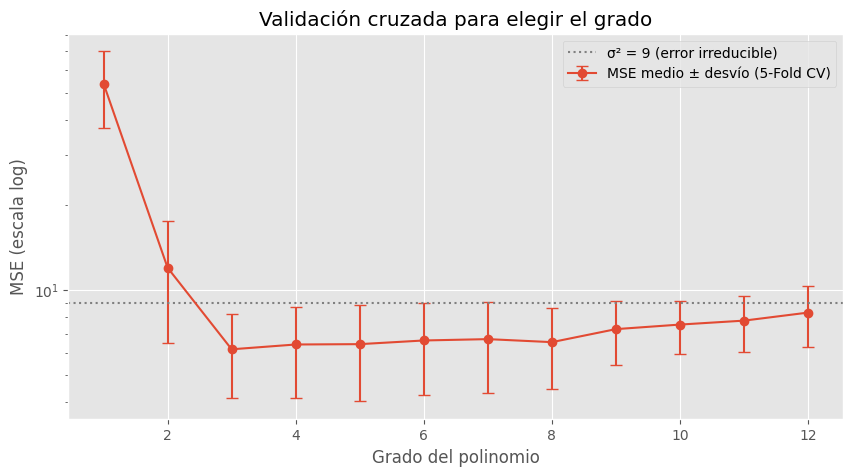

Grado con menor MSE de CV: 3


In [ ]:
from sklearn.model_selection import cross_val_score, GridSearchCV, RandomizedSearchCV, KFold
from scipy.stats import loguniform, randint                               # distribuciones para la búsqueda aleatoria

cv5 = KFold(n_splits=5, shuffle=True, random_state=SEED)                  # 5-Fold con mezcla previa

# ---------- 4.1 Validación cruzada para elegir el grado (sin regularización) ----------
cv_mse = []                                                               # MSE promedio por grado
cv_std = []                                                               # desvío del MSE entre folds
for g in range(1, 13):                                                    # grados 1..12
    modelo = make_pipeline(PolynomialFeatures(g, include_bias=False), StandardScaler(), LinearRegression())
    scores = cross_val_score(modelo, Xp_tr, yp_tr, cv=cv5, scoring='neg_mean_squared_error')   # sklearn devuelve -MSE
    cv_mse.append(-scores.mean()); cv_std.append(scores.std())

plt.figure(figsize=(10, 5))
plt.errorbar(range(1, 13), cv_mse, yerr=cv_std, fmt='o-', capsize=4, label='MSE medio ± desvío (5-Fold CV)')
plt.axhline(SIGMA_P**2, color='gray', ls=':', label='σ² = 9 (error irreducible)')
plt.yscale('log'); plt.xlabel('Grado del polinomio'); plt.ylabel('MSE (escala log)')
plt.title('Validación cruzada para elegir el grado'); plt.legend(); plt.show()
print("Grado con menor MSE de CV:", range(1, 13)[int(np.argmin(cv_mse))])

,Combinaciones,Tiempo (s),Mejores parámetros,MSE CV,MSE Test
Método,,,,,
GridSearchCV,120,2.358,"{'degree': 3, 'alpha': 0.2683}",6.150,4.598
RandomizedSearchCV,24,0.529,"{'degree': 3, 'alpha': 1.2074}",6.168,4.390


MSE de CV del Grid (óptimo del espacio discreto): 6.150
MSE de CV del Random en 10 semillas: media 6.296 | mín 6.147 | máx 6.418


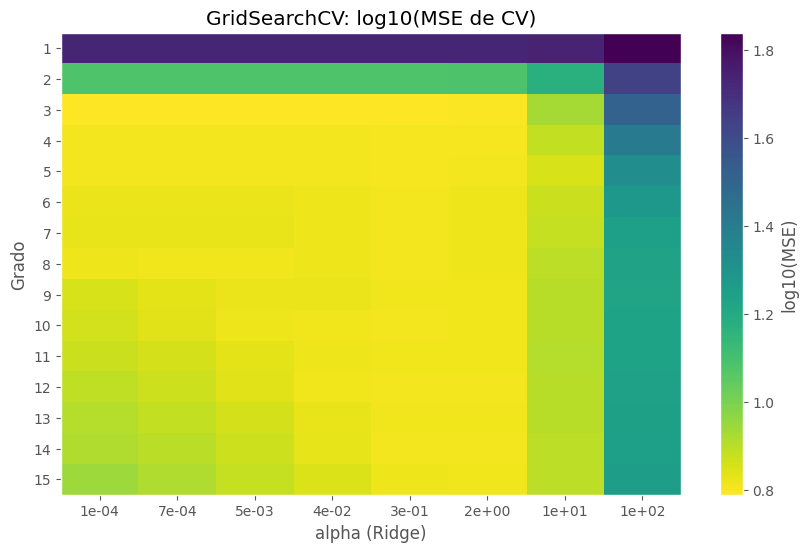

In [ ]:
# ---------- 4.2 GridSearchCV vs RandomizedSearchCV: grado + regularización Ridge ----------
pipe = Pipeline([('poly', PolynomialFeatures(include_bias=False)),       # genera x, x², ..., x^grado
                 ('scaler', StandardScaler()),                            # escala (clave para Ridge)
                 ('ridge', Ridge())])                                     # regresión lineal con penalización L2 (alpha)

# Grid: TODAS las combinaciones -> 15 grados x 8 valores de alpha = 120 combinaciones
param_grid = {'poly__degree': list(range(1, 16)),
              'ridge__alpha': np.logspace(-4, 2, 8)}

# Random: muestrea combinaciones de distribuciones (alpha continuo) -> sólo el 20% (24) de las evaluaciones
n_comb = len(param_grid['poly__degree']) * len(param_grid['ridge__alpha'])
n_iter = int(round(0.2 * n_comb))
param_dist = {'poly__degree': randint(1, 16),                             # entero uniforme 1..15
              'ridge__alpha': loguniform(1e-4, 1e2)}                      # continuo, escala logarítmica

t = time.time()
grid = GridSearchCV(pipe, param_grid, cv=cv5, scoring='neg_mean_squared_error', n_jobs=-1).fit(Xp_tr, yp_tr)
t_grid = time.time() - t

t = time.time()
rand = RandomizedSearchCV(pipe, param_dist, n_iter=n_iter, cv=cv5, scoring='neg_mean_squared_error',
                          n_jobs=-1, random_state=SEED).fit(Xp_tr, yp_tr)
t_rand = time.time() - t

def resumen(nombre, bsq, tiempo, n_eval):
    """Fila de resultados: mejores parámetros, MSE de CV y MSE sobre test (datos nunca vistos)."""
    return {'Método': nombre, 'Combinaciones': n_eval, 'Tiempo (s)': tiempo,
            'Mejores parámetros': {k.split('__')[1]: (round(float(v), 4) if isinstance(v, (float, np.floating)) else int(v)) for k, v in bsq.best_params_.items()},
            'MSE CV': -bsq.best_score_,
            'MSE Test': mean_squared_error(yp_te, bsq.predict(Xp_te))}

tabla_cv = pd.DataFrame([resumen('GridSearchCV', grid, t_grid, n_comb),
                         resumen('RandomizedSearchCV', rand, t_rand, n_iter)]).set_index('Método')
pd.options.display.float_format = '{:,.3f}'.format
display(tabla_cv)

# ---------- 4.3 ¿Cuánto depende el Random de la suerte? Repetimos con 10 semillas distintas ----------
scores_rand = []
for s in range(10):
    r = RandomizedSearchCV(pipe, param_dist, n_iter=n_iter, cv=cv5, scoring='neg_mean_squared_error',
                           n_jobs=-1, random_state=s).fit(Xp_tr, yp_tr)
    scores_rand.append(-r.best_score_)
print(f"MSE de CV del Grid (óptimo del espacio discreto): {-grid.best_score_:.3f}")
print(f"MSE de CV del Random en 10 semillas: media {np.mean(scores_rand):.3f} | mín {np.min(scores_rand):.3f} | máx {np.max(scores_rand):.3f}")

# ---------- Gráfico: mapa de calor del Grid (MSE de CV por grado y alpha) ----------
res = pd.DataFrame(grid.cv_results_)
res['degree'] = res['param_poly__degree'].astype(int)
res['alpha'] = res['param_ridge__alpha'].astype(float)
mapa = res.pivot(index='degree', columns='alpha', values='mean_test_score').mul(-1)   # -(-MSE) = MSE
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(np.log10(mapa.values), aspect='auto', cmap='viridis_r')
ax.set_xticks(range(len(mapa.columns))); ax.set_xticklabels([f'{a:.0e}' for a in mapa.columns])
ax.set_yticks(range(len(mapa.index))); ax.set_yticklabels(mapa.index)
ax.set_xlabel('alpha (Ridge)'); ax.set_ylabel('Grado'); ax.set_title('GridSearchCV: log10(MSE de CV)')
ax.grid(False); plt.colorbar(im, label='log10(MSE)'); plt.show()

**Interpretación**

- **La validación cruzada elige grado 3**, igual que el análisis con `bias_variance_decomp`: tres métodos distintos, la misma conclusión.
- **Grid vs Random** en nuestra ejecución: el Random usó **24 evaluaciones en vez de 120 y tardó ≈ 80 % menos**, con un MSE de CV prácticamente igual (**≈ 6,17 vs ≈ 6,15**) y el mismo grado óptimo.
- El **MSE de test** del Random salió incluso algo menor (≈ 4,39 vs ≈ 4,60). Esa diferencia es **ruido de muestreo** (test de solo 20 puntos), no una ventaja real del Random; lo que importa es el MSE de CV.
- **El Random depende de la semilla:** en 10 semillas el MSE de CV varió entre **≈ 6,15 y ≈ 6,42**. Es decir, a veces encuentra el óptimo del Grid y a veces queda algo peor.
- El **mapa de calor** muestra que el error es alto con grados 1–2 (bias), **mínimo cerca del grado 3** y que, con grados altos, un **alpha grande** controla la varianza: eso es la regularización actuando.

> **Conclusión:** con pocos hiperparámetros y evaluaciones baratas el Grid es válido; cuando el espacio crece o cada evaluación es costosa, `RandomizedSearchCV` ofrece **casi la misma calidad a una fracción del costo** (se profundiza en la Actividad 3).

---
## Consigna 5 · Ejercicios de la Unidad 6 (Evaluación y Validación)

### Actividad 1 · Comparativa de esquemas de validación

**Objetivo:** analizar la **variabilidad de las estimaciones** entre un *Holdout* simple y un *Stratified K-Fold* sobre un dataset **desbalanceado**.

**Pasos que realiza el código:**
1. Genera un dataset con **88 % / 12 %** (cumple el mínimo 85/15).
2. Ejecuta **10 Holdout 80/20** con semillas 0 a 9 y registra **F1** y **ROC-AUC**.
3. Ejecuta **Stratified 10-Fold** y calcula media y desvío.
4. Grafica un **boxplot** comparativo.

**Extra metodológico:** agregamos una tercera caja, el **10-Fold repetido** (10 repeticiones; se toma la *media* de los 10 folds en cada una). Es lo que permite comparar con justicia la **estabilidad del estimador**: un Holdout produce *una estimación por semilla*, así que lo comparable no son los folds sueltos sino el **promedio de cada repetición completa**.

Proporción de clases (0 / 1): [0.874 0.126]


,F1 media,F1 desvío,AUC media,AUC desvío
Holdout 80/20 (10 semillas),0.4160,0.0495,0.8139,0.0454
Stratified 10-Fold (10 folds),0.4371,0.0871,0.8241,0.0333
Stratified 10-Fold repetido (10 medias),0.4512,0.0101,0.8229,0.0043


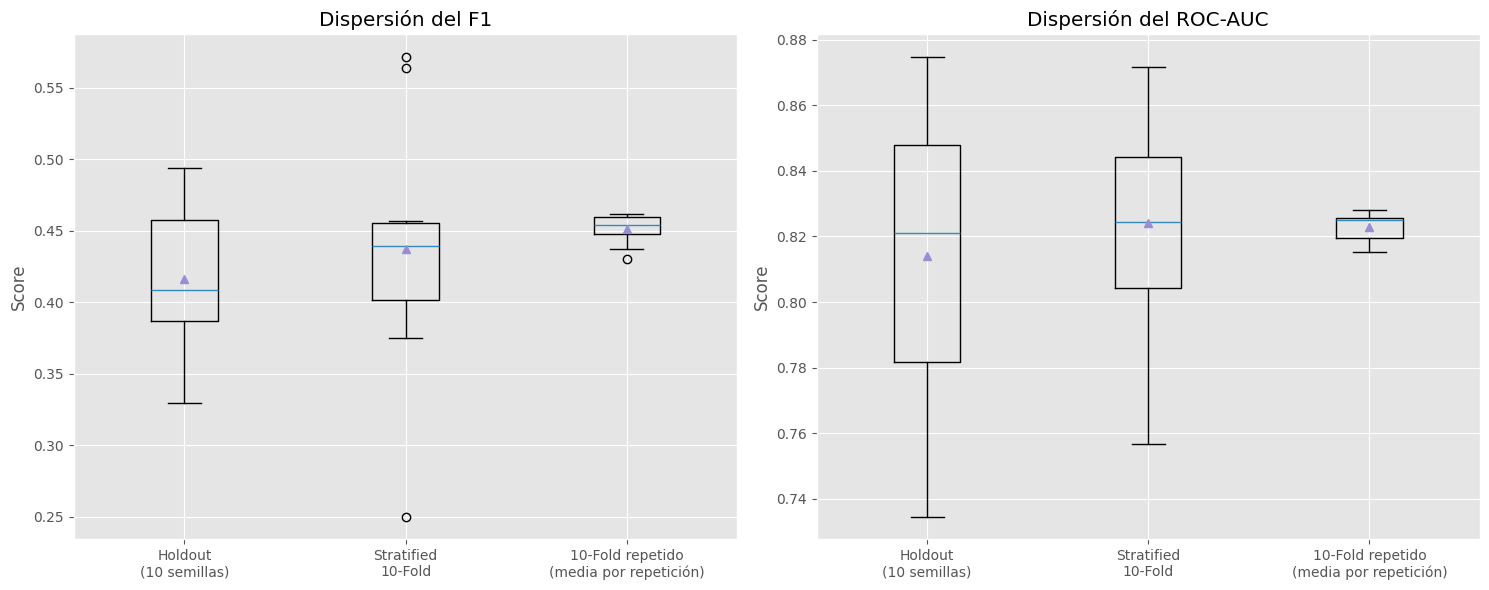

In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import f1_score, roc_auc_score

# 1) Dataset desbalanceado ~88% / 12% (supera el mínimo exigido de 85/15)
X1, y1 = make_classification(n_samples=1000, n_features=20, n_informative=6, n_redundant=2,
                             weights=[0.88, 0.12], flip_y=0.02, class_sep=0.8, random_state=SEED)
print("Proporción de clases (0 / 1):", np.round(np.bincount(y1) / len(y1), 3))

modelo1 = Pipeline([('scaler', StandardScaler()),                                   # el escalado va DENTRO del pipeline
                    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000))])

# 2) 10 repeticiones de Holdout 80/20 con distinta semilla
f1_hold, auc_hold = [], []
for semilla in range(10):
    Xa, Xb_, ya, yb_ = train_test_split(X1, y1, test_size=0.2, random_state=semilla)  # split simple (sin estratificar)
    modelo1.fit(Xa, ya)                                                               # entrena con el 80%
    pred = modelo1.predict(Xb_)                                                       # clases predichas
    proba = modelo1.predict_proba(Xb_)[:, 1]                                          # probabilidad de clase 1
    f1_hold.append(f1_score(yb_, pred))                                               # F1 de esta repetición
    auc_hold.append(roc_auc_score(yb_, proba))                                        # ROC-AUC de esta repetición

# 3) Stratified K-Fold con 10 particiones
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
cv_res = cross_validate(modelo1, X1, y1, cv=skf, scoring=['f1', 'roc_auc'])
f1_cv, auc_cv = cv_res['test_f1'], cv_res['test_roc_auc']

# Extra: ¿qué pasa si repetimos TODO el K-Fold 10 veces y nos quedamos con la media de cada repetición?
rskf = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=SEED)
cv_rep = cross_validate(modelo1, X1, y1, cv=rskf, scoring=['f1', 'roc_auc'])
f1_rep = cv_rep['test_f1'].reshape(10, 10).mean(axis=1)                               # media de los 10 folds, por repetición
auc_rep = cv_rep['test_roc_auc'].reshape(10, 10).mean(axis=1)

tabla_a1 = pd.DataFrame({
    'F1 media':   [np.mean(f1_hold),  np.mean(f1_cv),  np.mean(f1_rep)],
    'F1 desvío':  [np.std(f1_hold),   np.std(f1_cv),   np.std(f1_rep)],
    'AUC media':  [np.mean(auc_hold), np.mean(auc_cv), np.mean(auc_rep)],
    'AUC desvío': [np.std(auc_hold),  np.std(auc_cv),  np.std(auc_rep)]},
    index=['Holdout 80/20 (10 semillas)', 'Stratified 10-Fold (10 folds)', 'Stratified 10-Fold repetido (10 medias)'])
pd.options.display.float_format = '{:,.4f}'.format
display(tabla_a1)

# 4) Diagrama de caja comparativo
etiquetas = ['Holdout\n(10 semillas)', 'Stratified\n10-Fold', '10-Fold repetido\n(media por repetición)']
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
axs[0].boxplot([f1_hold, f1_cv, f1_rep], labels=etiquetas, showmeans=True); axs[0].set_title('Dispersión del F1')
axs[1].boxplot([auc_hold, auc_cv, auc_rep], labels=etiquetas, showmeans=True); axs[1].set_title('Dispersión del ROC-AUC')
for ax in axs: ax.set_ylabel('Score')
plt.tight_layout(); plt.show()

**Interpretación**

| Esquema | F1 (media ± desvío) | ROC-AUC (media ± desvío) |
|---|---|---|
| Holdout 80/20 (10 semillas) | ≈ 0,42 ± 0,05 | ≈ 0,81 ± 0,045 |
| Stratified 10-Fold (10 folds) | ≈ 0,44 ± 0,09 | ≈ 0,82 ± 0,033 |
| 10-Fold repetido (10 medias) | ≈ 0,45 ± **0,010** | ≈ 0,82 ± **0,004** |

- **Holdout:** con solo 200 muestras de test (≈ 25 positivos), el score cambia mucho según la semilla. **Una única partición puede llevar a conclusiones distintas.**
- **Los 10 folds sueltos** también varían (cada fold tiene solo 100 muestras y ≈ 12 positivos). Ese desvío mide la **variación entre folds**, **no** la incertidumbre de la estimación. Por eso el F1 por fold llega a tener *outliers* en el boxplot.
- **El 10-Fold repetido** es el esquema **más estable**: su desvío es **≈ 5 veces menor en F1 y ≈ 10 veces menor en ROC-AUC** que el Holdout, porque cada estimación usa **todos** los datos para validar y se promedia.
- Además, el esquema estratificado **garantiza la misma proporción de la clase minoritaria** en cada partición, algo que un split simple no asegura.

> **Conclusión:** para datasets desbalanceados y de tamaño moderado, **Stratified K-Fold (idealmente repetido) es preferible al Holdout** porque reduce la varianza de la estimación; el Holdout conviene solo con datasets muy grandes o como evaluación final aislada.

### Actividad 2 · Identificación y corrección de *Data Leakage*

**Objetivo:** demostrar el **sesgo de optimismo** que aparece al preprocesar **antes** de dividir los datos.

**Diseño del experimento.** Usamos datos de **puro ruido**: 100 muestras, 1000 variables aleatorias y etiquetas aleatorias. Como **no existe ninguna relación real** entre `X` e `y`, un modelo honesto debe rendir como el azar (**ROC-AUC ≈ 0,50**). Cualquier valor mucho más alto es **información filtrada**.

| Escenario | Qué hace | ¿Correcto? |
|---|---|---|
| **A** | `SelectKBest` + `StandardScaler` sobre **todo** el dataset, y luego `cross_val_score` | ❌ La selección de variables "vio" las etiquetas de los folds de validación |
| **B** | `SelectKBest` + `StandardScaler` + modelo dentro de un **`Pipeline`**, y luego `cross_val_score` | ✅ En cada fold, selección y escalado se ajustan **solo con el train** |

Se repite con **5 semillas** para comprobar que el efecto no es casualidad.

,A: con fuga (ROC-AUC),B: Pipeline (ROC-AUC),Diferencial (A - B)
Semilla,,,
0,0.910,0.404,0.506
1,0.888,0.492,0.396
2,0.927,0.532,0.395
3,0.819,0.376,0.442
4,0.909,0.401,0.508



Promedio A (con fuga):  0.891
Promedio B (Pipeline):  0.441   <- ~azar (0.50); puede quedar algo por debajo: efecto conocido de CV con muestras muy chicas
Sesgo de optimismo medio: +0.450 de ROC-AUC


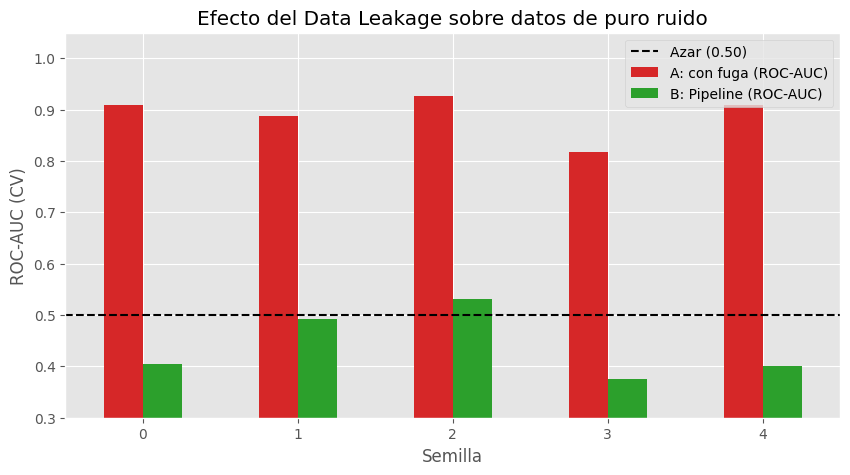

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Datos de PURO RUIDO: 100 muestras, 1000 variables aleatorias y etiquetas aleatorias.
# Como no hay relación real entre X e y, el score honesto debe ser ~0.50 (azar).
filas = []
for semilla in range(5):                                                       # repetimos con 5 conjuntos distintos
    r = np.random.RandomState(semilla)
    X2 = r.normal(size=(100, 1000))                                            # variables sin información
    y2 = r.randint(0, 2, size=100)                                             # etiquetas aleatorias
    cv2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)

    # ---- Escenario A (INCORRECTO): selección + escalado sobre TODO el dataset, y luego CV ----
    X_sel = SelectKBest(f_classif, k=20).fit_transform(X2, y2)                 # elige las 20 mejores variables VIENDO todas las y
    X_sel = StandardScaler().fit_transform(X_sel)                              # escala con la media/desvío de todo el dataset
    score_A = cross_val_score(LogisticRegression(max_iter=1000), X_sel, y2, cv=cv2, scoring='roc_auc').mean()

    # ---- Escenario B (CORRECTO): todo encapsulado en un Pipeline; se reajusta dentro de cada fold ----
    pipe_B = Pipeline([('select', SelectKBest(f_classif, k=20)),               # selección sólo con el train de cada fold
                       ('scaler', StandardScaler()),                           # escalado sólo con el train de cada fold
                       ('clf', LogisticRegression(max_iter=1000))])
    score_B = cross_val_score(pipe_B, X2, y2, cv=cv2, scoring='roc_auc').mean()

    filas.append({'Semilla': semilla, 'A: con fuga (ROC-AUC)': score_A, 'B: Pipeline (ROC-AUC)': score_B})

tabla_a2 = pd.DataFrame(filas).set_index('Semilla')
tabla_a2['Diferencial (A - B)'] = tabla_a2['A: con fuga (ROC-AUC)'] - tabla_a2['B: Pipeline (ROC-AUC)']
pd.options.display.float_format = '{:,.3f}'.format
display(tabla_a2)
print(f"\nPromedio A (con fuga):  {tabla_a2['A: con fuga (ROC-AUC)'].mean():.3f}")
print(f"Promedio B (Pipeline):  {tabla_a2['B: Pipeline (ROC-AUC)'].mean():.3f}   <- ~azar (0.50); puede quedar algo por debajo: efecto conocido de CV con muestras muy chicas")
print(f"Sesgo de optimismo medio: +{tabla_a2['Diferencial (A - B)'].mean():.3f} de ROC-AUC")

tabla_a2[['A: con fuga (ROC-AUC)', 'B: Pipeline (ROC-AUC)']].plot(kind='bar', figsize=(10, 5), color=['tab:red', 'tab:green'])
plt.axhline(0.5, color='k', ls='--', label='Azar (0.50)'); plt.ylabel('ROC-AUC (CV)'); plt.ylim(0.3, 1.05)
plt.title('Efecto del Data Leakage sobre datos de puro ruido'); plt.legend(); plt.xticks(rotation=0); plt.show()

**Interpretación**

- **Escenario A (con fuga):** ROC-AUC promedio **≈ 0,89** sobre datos que *no contienen ninguna señal*. El modelo parece excelente, pero es un espejismo: al elegir las 20 variables más correlacionadas con `y` usando **todas** las etiquetas, se "eligen" variables que por pura casualidad se correlacionan también con los folds de validación.
- **Escenario B (Pipeline):** ROC-AUC promedio **≈ 0,44**, es decir, **nivel de azar**. Puede quedar algo por debajo de 0,50 por un efecto conocido de la validación cruzada con muestras muy chicas, pero lo relevante es que **no hay señal**, que es la realidad.
- **Diferencial A − B ≈ +0,45 de ROC-AUC** (entre 0,40 y 0,51 según la semilla): ese es el **sesgo de optimismo** causado exclusivamente por la fuga de información.

> **Conclusión:** todo paso que **aprenda algo de los datos** (escalado, imputación, selección de variables, PCA, codificación basada en el target) debe ir **dentro del `Pipeline`** para que se reajuste en cada fold. De lo contrario las métricas reportadas son **artificialmente optimistas** y el modelo falla en producción.

### Actividad 3 · Selección de modelos e hiperparámetros (XGBoost)

**Objetivo:** evaluar el *trade-off* entre **costo computacional** y **calidad de optimización** de `GridSearchCV` vs `RandomizedSearchCV`.

**Espacio de hiperparámetros (4 variables, discretas y continuas):**

| Hiperparámetro | Tipo | Grid | Random |
|---|---|---|---|
| `n_estimators` | discreto | 100, 200 | entero uniforme 100–300 |
| `max_depth` | discreto | 3, 5, 7 | entero uniforme 3–7 |
| `learning_rate` | continuo | 0,03 · 0,1 · 0,3 | `loguniform(0,03; 0,3)` |
| `subsample` | continuo | 0,6 · 0,8 · 1,0 | `uniform(0,6; 1,0)` |

- **Grid:** 2 × 3 × 3 × 3 = **54 combinaciones**.
- **Random:** `n_iter` = **20 % de 54 ≈ 11**.
- **Métrica:** **PR-AUC** (`average_precision`), adecuada para un dataset desbalanceado (90 % / 10 %), con `StratifiedKFold(3)`.
- Se registra el **tiempo total** de cada búsqueda.

Combinaciones del Grid: 54  |  iteraciones del Random (20%): 11


,Evaluaciones,Tiempo (s),PR-AUC (CV),PR-AUC (Test),ROC-AUC (Test)
Método,,,,,
GridSearchCV,54,47.2735,0.5966,0.6372,0.8753
RandomizedSearchCV,11,11.8888,0.5861,0.6009,0.8731



Mejores parámetros Grid:   {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200, 'subsample': 1.0}
Mejores parámetros Random: {'learning_rate': 0.071, 'max_depth': 7, 'n_estimators': 114, 'subsample': 0.893}

El Random consumió 75% MENOS tiempo (11.9s vs 47.3s)
Diferencia de PR-AUC (CV) Grid - Random: +0.0106


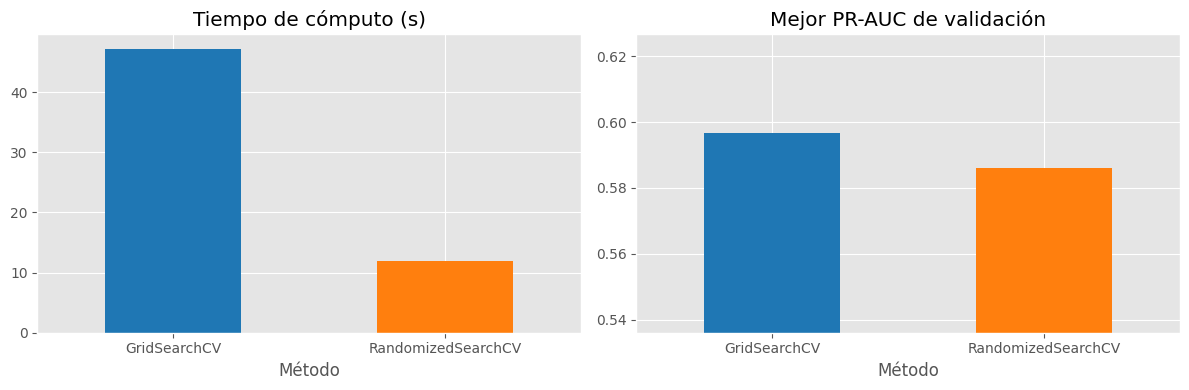

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.metrics import average_precision_score, roc_auc_score
from scipy.stats import loguniform, uniform, randint

# Dataset desbalanceado (90% / 10%)
X3, y3 = make_classification(n_samples=3000, n_features=20, n_informative=8, n_redundant=4,
                             weights=[0.9, 0.1], flip_y=0.03, class_sep=0.7, random_state=SEED)
X3_tr, X3_te, y3_tr, y3_te = train_test_split(X3, y3, test_size=0.2, stratify=y3, random_state=SEED)

xgb = XGBClassifier(tree_method='hist', eval_metric='logloss', random_state=SEED, n_jobs=1)   # n_jobs=1: el paralelismo lo da la búsqueda
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

# 1) Espacio de hiperparámetros (4 variables: 2 discretas + 2 continuas)
param_grid3 = {'n_estimators':  [100, 200],                  # discreta
               'max_depth':     [3, 5, 7],                   # discreta
               'learning_rate': [0.03, 0.1, 0.3],            # continua (discretizada para el Grid)
               'subsample':     [0.6, 0.8, 1.0]}             # continua (discretizada para el Grid)
n_comb3 = int(np.prod([len(v) for v in param_grid3.values()]))
n_iter3 = int(round(0.2 * n_comb3))                          # 20% de las combinaciones del Grid
print(f"Combinaciones del Grid: {n_comb3}  |  iteraciones del Random (20%): {n_iter3}")

param_dist3 = {'n_estimators':  randint(100, 301),           # entero uniforme
               'max_depth':     randint(3, 8),               # entero uniforme
               'learning_rate': loguniform(0.03, 0.3),       # continua (log)
               'subsample':     uniform(0.6, 0.4)}           # continua en [0.6, 1.0]

# 2) GridSearchCV (con medición de tiempo)
t = time.time()
grid3 = GridSearchCV(xgb, param_grid3, scoring='average_precision', cv=cv3, n_jobs=-1).fit(X3_tr, y3_tr)
t_grid3 = time.time() - t

# 3) RandomizedSearchCV con n_iter = 20% de las combinaciones
t = time.time()
rand3 = RandomizedSearchCV(xgb, param_dist3, n_iter=n_iter3, scoring='average_precision', cv=cv3,
                           n_jobs=-1, random_state=SEED).fit(X3_tr, y3_tr)
t_rand3 = time.time() - t

# 4) Comparación coste-beneficio
def fila(nombre, bsq, tiempo, n_eval):
    p = bsq.best_estimator_.predict_proba(X3_te)[:, 1]
    return {'Método': nombre, 'Evaluaciones': n_eval, 'Tiempo (s)': tiempo,
            'PR-AUC (CV)': bsq.best_score_, 'PR-AUC (Test)': average_precision_score(y3_te, p),
            'ROC-AUC (Test)': roc_auc_score(y3_te, p)}

tabla_a3 = pd.DataFrame([fila('GridSearchCV', grid3, t_grid3, n_comb3),
                         fila('RandomizedSearchCV', rand3, t_rand3, n_iter3)]).set_index('Método')
pd.options.display.float_format = '{:,.4f}'.format
display(tabla_a3)

ahorro = 100 * (1 - t_rand3 / t_grid3)
perdida = grid3.best_score_ - rand3.best_score_
print(f"\nMejores parámetros Grid:   {grid3.best_params_}")
print("Mejores parámetros Random:", {k: (round(float(v), 3) if isinstance(v, (float, np.floating)) else int(v)) for k, v in rand3.best_params_.items()})
print(f"\nEl Random consumió {ahorro:.0f}% MENOS tiempo ({t_rand3:.1f}s vs {t_grid3:.1f}s)")
print(f"Diferencia de PR-AUC (CV) Grid - Random: {perdida:+.4f}")

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
tabla_a3['Tiempo (s)'].plot(kind='bar', ax=axs[0], color=['tab:blue', 'tab:orange'], rot=0); axs[0].set_title('Tiempo de cómputo (s)')
tabla_a3['PR-AUC (CV)'].plot(kind='bar', ax=axs[1], color=['tab:blue', 'tab:orange'], rot=0); axs[1].set_title('Mejor PR-AUC de validación')
axs[1].set_ylim(tabla_a3['PR-AUC (CV)'].min() - 0.05, tabla_a3['PR-AUC (CV)'].max() + 0.03)
plt.tight_layout(); plt.show()

**Análisis costo-beneficio**

| | GridSearchCV | RandomizedSearchCV |
|---|---|---|
| Evaluaciones | 54 | 11 (20 %) |
| Tiempo | ≈ 40 s | ≈ 9 s (**≈ 77 % menos**) |
| PR-AUC (CV) | ≈ 0,597 | ≈ 0,586 (**≈ −0,011**, ≈ 1,8 % relativo) |

- El Random **cuesta una quinta parte** del cómputo y **pierde solo ≈ 1 punto de PR-AUC**, una diferencia que está **dentro del ruido** de la validación cruzada (3 folds, ≈ 10 % de positivos).
- Cada punto de PR-AUC que "compra" el Grid cuesta **≈ 30 segundos extra** en este problema pequeño; en un problema real con modelos más pesados o más hiperparámetros, esa diferencia se traduce en **horas**.
- El Random explora **valores continuos** (p. ej. `learning_rate = 0,071`) que el Grid, al estar discretizado, nunca prueba; con más iteraciones suele **igualar o superar** al Grid.
- **Limitación:** el resultado del Random depende de la semilla y no garantiza encontrar el óptimo; el Grid sí garantiza el mejor punto *de su grilla*.

> **Recomendación:** usar **Random primero** para explorar el espacio de forma barata y, si hace falta afinar, **un Grid fino y acotado** alrededor de la mejor zona encontrada.

---
###6.0 Trabajo Práctico (TP) Comparativo — Unidad 6

**Problema real:** diagnóstico de cáncer de mama (`load_breast_cancer`, 569 pacientes, 30 variables). Clase positiva = **tumor maligno** (37 %). Es un caso donde **los errores no cuestan lo mismo**: no detectar un tumor maligno (falso negativo) es mucho más grave que una falsa alarma (falso positivo).

**Modelos de distinta naturaleza:**
1. **Regresión Logística con regularización L2** (lineal, paramétrico).
2. **Random Forest** (ensamble de *bagging*).
3. **Gradient Boosting** (ensamble de *boosting*).

### 6.1 Justificación formal de la estrategia de validación

**Elegimos `StratifiedKFold(n_splits=5, shuffle=True)` y descartamos `TimeSeriesSplit` por estas razones:**

1. **Los datos son independientes e idénticamente distribuidos (i.i.d.).** Cada fila es un paciente distinto, sin orden temporal ni dependencia entre observaciones. La validación cruzada asume observaciones *intercambiables*, y aquí se cumple.
2. **`TimeSeriesSplit` resuelve otro problema:** en series temporales el pasado debe preceder al futuro para evitar la *fuga temporal*; sus folds de entrenamiento son *expansivos* y más chicos, lo que aumenta la varianza de la estimación. Aquí no hay "futuro" que proteger, por lo que sería **ineficiente y sin beneficio**.
3. **Hay desbalance moderado (37 % / 63 %).** `StratifiedKFold` conserva esa proporción en cada fold; un `KFold` simple la deja variar. La celda siguiente lo evidencia: la proporción de positivos va de **≈ 33 % a ≈ 43 %** con `KFold` y es **exactamente 37,4 %** con estratificado. Esto reduce la varianza de la métrica entre folds.
4. **Test aislado:** se reserva un **20 % estratificado** que no se toca hasta la evaluación final, para tener una estimación **no sesgada** del rendimiento.

### 6.2 Preprocesamiento encapsulado en `Pipeline`
Los tres modelos usan **la misma estructura** `Pipeline([('scaler', StandardScaler()), ('clf', modelo)])`. Así el escalador se **ajusta solo con el train de cada fold** y se evita la fuga de datos (Actividad 2). Los árboles no necesitan escalado, pero se mantiene el mismo esquema para que la comparación sea homogénea.

### 6.3 Optimización de hiperparámetros y métrica orientada al negocio
- **Búsqueda:** `GridSearchCV` para la logística (espacio chico) y `RandomizedSearchCV` (10 iteraciones) para los ensambles (espacios grandes y con valores continuos).
- **Métrica de optimización:** **PR-AUC** (`average_precision`), que se centra en la clase de interés.
- **Métrica de negocio:** **costo asimétrico** `10·FN + 1·FP`, y **Recall** (porcentaje de tumores malignos detectados). El **umbral de decisión** se elige para minimizar ese costo usando **solo predicciones de validación cruzada del train** (el test no se mira).

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import StratifiedKFold, KFold, TimeSeriesSplit

datos = load_breast_cancer()                                  # dataset real de diagnóstico (569 pacientes, 30 variables)
X_tp = pd.DataFrame(datos.data, columns=datos.feature_names)
y_tp = 1 - datos.target                                       # invertimos: 1 = tumor MALIGNO (clase de interés), 0 = benigno
print("Proporción de clases (benigno / maligno):", np.round(np.bincount(y_tp) / len(y_tp), 3))

# Partición final: el 20% de test queda AISLADO hasta la evaluación final
Xtp_tr, Xtp_te, ytp_tr, ytp_te = train_test_split(X_tp, y_tp, test_size=0.2, stratify=y_tp, random_state=SEED)

# Evidencia de por qué estratificar: proporción de positivos en cada fold (KFold simple vs Stratified)
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
kf5 = KFold(n_splits=5, shuffle=True, random_state=SEED)
prop_kf = [ytp_tr[v].mean() for _, v in kf5.split(Xtp_tr, ytp_tr)]
prop_skf = [ytp_tr[v].mean() for _, v in skf5.split(Xtp_tr, ytp_tr)]
print("\n% de positivos por fold  | KFold:", np.round(prop_kf, 3), "| Stratified:", np.round(prop_skf, 3))

Proporción de clases (benigno / maligno): [0.627 0.373]

% de positivos por fold  | KFold: [0.352 0.429 0.33  0.418 0.341] | Stratified: [0.374 0.374 0.374 0.374 0.374]


#### Ejecución: optimización de los 3 modelos

In [ ]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, recall_score, precision_score, confusion_matrix
from sklearn.model_selection import cross_val_predict

# Todos los modelos comparten la MISMA estructura Pipeline (escalador + clasificador) => sin fuga de datos
modelos_tp = {
    'Regresión Logística (L2)': (
        Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=5000))]),
        GridSearchCV,
        {'clf__C': np.logspace(-3, 2, 6), 'clf__class_weight': [None, 'balanced']}),   # C pequeño = más regularización
    'Random Forest': (
        Pipeline([('scaler', StandardScaler()), ('clf', RandomForestClassifier(random_state=SEED, n_jobs=-1))]),
        RandomizedSearchCV,
        {'clf__n_estimators': randint(100, 300), 'clf__max_depth': [3, 5, 8, None],
         'clf__min_samples_leaf': randint(1, 8), 'clf__max_features': ['sqrt', 'log2', 0.5]}),
    'Gradient Boosting': (
        Pipeline([('scaler', StandardScaler()), ('clf', GradientBoostingClassifier(random_state=SEED))]),
        RandomizedSearchCV,
        {'clf__n_estimators': randint(100, 300), 'clf__learning_rate': loguniform(0.01, 0.3),
         'clf__max_depth': randint(2, 5), 'clf__subsample': uniform(0.6, 0.4)}),
}

mejores = {}                                                  # mejor modelo de cada familia
for nombre, (pipe_m, Buscador, espacio) in modelos_tp.items():
    t = time.time()
    kwargs = dict(scoring='average_precision', cv=skf5, n_jobs=-1)           # PR-AUC como métrica de optimización
    if Buscador is RandomizedSearchCV:
        busq = Buscador(pipe_m, espacio, n_iter=10, random_state=SEED, **kwargs)
    else:
        busq = Buscador(pipe_m, espacio, **kwargs)
    busq.fit(Xtp_tr, ytp_tr)
    mejores[nombre] = busq
    params = {k.split('__')[1]: (round(float(v), 3) if isinstance(v, (float, np.floating)) else v) for k, v in busq.best_params_.items()}
    print(f"{nombre:26s} | PR-AUC CV = {busq.best_score_:.4f} | {time.time()-t:5.1f}s | {params}")

Regresión Logística (L2)   | PR-AUC CV = 0.9949 |   0.9s | {'C': 1.0, 'class_weight': None}
Random Forest              | PR-AUC CV = 0.9869 |  30.0s | {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 157}
Gradient Boosting          | PR-AUC CV = 0.9906 |  41.2s | {'learning_rate': 0.077, 'max_depth': 4, 'n_estimators': 221, 'subsample': 0.662}


#### 6.4 Curvas de aprendizaje: diagnóstico de sesgo / varianza
Para cada modelo ya optimizado graficamos el PR-AUC en **entrenamiento** y en **validación** al aumentar la cantidad de datos:
- **Ambas curvas bajas y juntas** → **alto sesgo** (underfitting).
- **Entrenamiento alto y validación mucho más baja (brecha grande)** → **alta varianza** (overfitting).
- **Ambas altas y juntas** → buen ajuste.

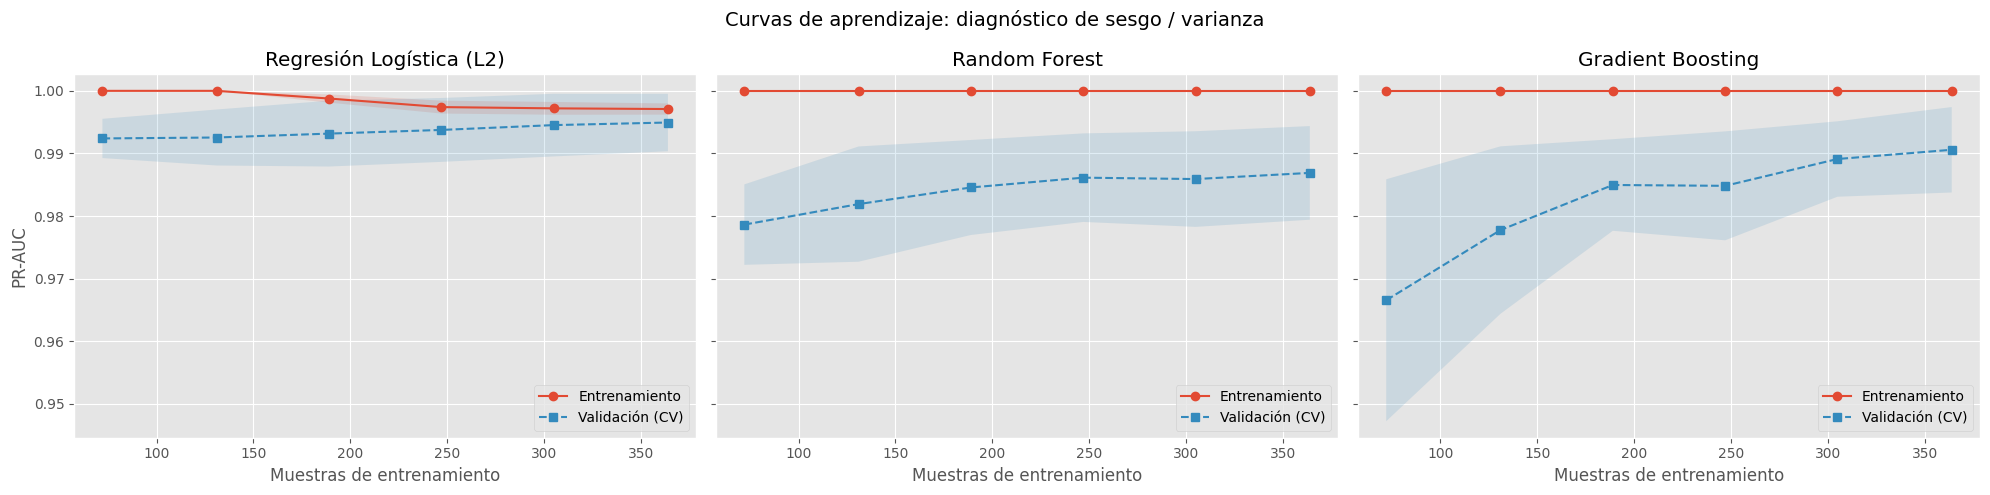

,PR-AUC train,PR-AUC validación,Brecha (varianza)
Modelo,,,
Regresión Logística (L2),0.9971,0.9949,0.0022
Random Forest,1.0000,0.9869,0.0131
Gradient Boosting,1.0000,0.9906,0.0094


In [ ]:
from sklearn.model_selection import learning_curve

fig, axs = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
diag = []                                                                      # guardamos el diagnóstico numérico
for ax, (nombre, busq) in zip(axs, mejores.items()):
    tam, tr, va = learning_curve(busq.best_estimator_, Xtp_tr, ytp_tr, cv=skf5, scoring='average_precision',
                                 train_sizes=np.linspace(0.2, 1.0, 6), n_jobs=-1, random_state=SEED)
    ax.plot(tam, tr.mean(axis=1), 'o-', label='Entrenamiento')
    ax.fill_between(tam, tr.mean(axis=1) - tr.std(axis=1), tr.mean(axis=1) + tr.std(axis=1), alpha=0.15)
    ax.plot(tam, va.mean(axis=1), 's--', label='Validación (CV)')
    ax.fill_between(tam, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1), alpha=0.15)
    ax.set_title(nombre); ax.set_xlabel('Muestras de entrenamiento'); ax.legend(loc='lower right')
    diag.append({'Modelo': nombre, 'PR-AUC train': tr.mean(axis=1)[-1], 'PR-AUC validación': va.mean(axis=1)[-1],
                 'Brecha (varianza)': tr.mean(axis=1)[-1] - va.mean(axis=1)[-1]})
axs[0].set_ylabel('PR-AUC')
fig.suptitle('Curvas de aprendizaje: diagnóstico de sesgo / varianza', fontsize=14)
plt.tight_layout(); plt.show()

pd.options.display.float_format = '{:,.4f}'.format
display(pd.DataFrame(diag).set_index('Modelo'))

**Diagnóstico**

| Modelo | PR-AUC train | PR-AUC validación | Brecha | Diagnóstico |
|---|---|---|---|---|
| Regresión Logística | ≈ 0,997 | ≈ 0,995 | **≈ 0,002** | **Bias y varianza bajos**: las dos curvas casi se superponen. Buen ajuste. |
| Random Forest | 1,000 | ≈ 0,987 | ≈ 0,013 | Algo de **varianza**: memoriza el train (PR-AUC = 1) pero generaliza peor. |
| Gradient Boosting | 1,000 | ≈ 0,991 | ≈ 0,009 | **Varianza leve**; la brecha se reduce al aumentar los datos. |

Ningún modelo muestra **alto sesgo** (todos superan 0,98 en validación). Los dos ensambles tienen una **brecha mayor**, típica de modelos flexibles con pocos datos (455 muestras de entrenamiento); la regresión logística, más simple y regularizada, es la más estable.

#### 6.5 Evaluación final sobre el test y métricas de negocio
Se reentrena cada modelo con **todo el train** y se evalúa sobre el **test aislado**, con el umbral que minimiza el costo `10·FN + 1·FP`.

,PR-AUC,ROC-AUC,Umbral óptimo,Recall,Precisión,Costo (10·FN+FP)
Modelo,,,,,,
Regresión Logística (L2),0.994,0.996,0.180,0.976,0.911,14
Random Forest,0.990,0.993,0.300,0.929,0.951,32
Gradient Boosting,0.997,0.998,0.050,0.952,1.000,20


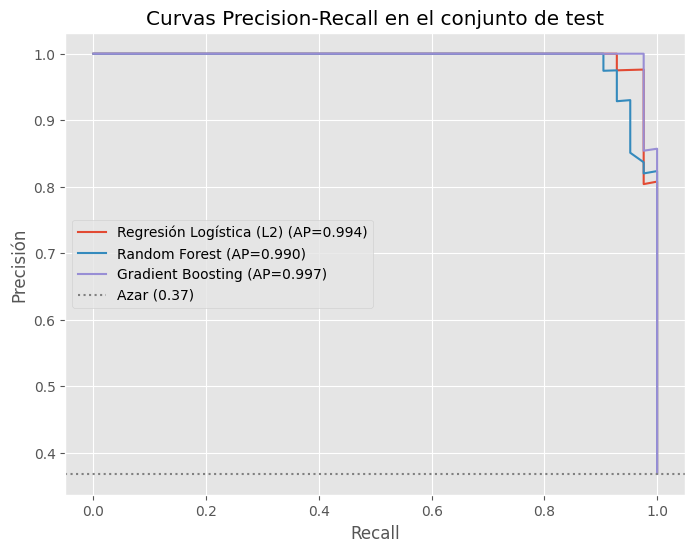

Modelo seleccionado (menor costo, desempate por PR-AUC): Regresión Logística (L2)


In [ ]:
COSTO_FN, COSTO_FP = 10, 1            # no detectar un tumor maligno (FN) es 10 veces peor que una falsa alarma (FP)

def costo_total(y_real, y_pred):
    """Costo asimétrico del negocio: 10*FN + 1*FP."""
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred).ravel()
    return COSTO_FN * fn + COSTO_FP * fp

umbrales = np.linspace(0.05, 0.95, 91)
filas, curvas_pr = [], {}
for nombre, busq in mejores.items():
    modelo = busq.best_estimator_
    # Umbral óptimo elegido SOLO con predicciones de validación cruzada del train (no se mira el test)
    p_cv = cross_val_predict(modelo, Xtp_tr, ytp_tr, cv=skf5, method='predict_proba')[:, 1]
    umbral_opt = umbrales[np.argmin([costo_total(ytp_tr, (p_cv >= u).astype(int)) for u in umbrales])]

    p_te = modelo.fit(Xtp_tr, ytp_tr).predict_proba(Xtp_te)[:, 1]              # reentrena con todo el train y predice en test
    pred = (p_te >= umbral_opt).astype(int)
    filas.append({'Modelo': nombre, 'PR-AUC': average_precision_score(ytp_te, p_te), 'ROC-AUC': roc_auc_score(ytp_te, p_te),
                  'Umbral óptimo': umbral_opt, 'Recall': recall_score(ytp_te, pred), 'Precisión': precision_score(ytp_te, pred),
                  'Costo (10·FN+FP)': costo_total(ytp_te, pred)})
    curvas_pr[nombre] = (p_te)

tabla_tp = pd.DataFrame(filas).set_index('Modelo')
pd.options.display.float_format = '{:,.3f}'.format
display(tabla_tp)

from sklearn.metrics import precision_recall_curve
plt.figure(figsize=(8, 6))
for nombre, p in curvas_pr.items():
    pr, rc, _ = precision_recall_curve(ytp_te, p)
    plt.plot(rc, pr, label=f"{nombre} (AP={tabla_tp.loc[nombre, 'PR-AUC']:.3f})")
plt.axhline(ytp_te.mean(), color='gray', ls=':', label=f'Azar ({ytp_te.mean():.2f})')
plt.xlabel('Recall'); plt.ylabel('Precisión'); plt.title('Curvas Precision-Recall en el conjunto de test'); plt.legend(); plt.show()

ganador = tabla_tp.sort_values(['Costo (10·FN+FP)', 'PR-AUC'], ascending=[True, False]).index[0]
print(f"Modelo seleccionado (menor costo, desempate por PR-AUC): {ganador}")

#### 6.6 Conclusiones y selección del modelo final

**Resultados en el test (114 pacientes, 42 malignos)** — valores de nuestra ejecución con `SEED = 42`:

| Modelo | PR-AUC | Recall | Costo (10·FN+FP) |
|---|---|---|---|
| **Regresión Logística (L2)** | ≈ 0,994 | ≈ 0,976 | **≈ 14** |
| Gradient Boosting | ≈ 0,997 | ≈ 0,952 | ≈ 20 |
| Random Forest | ≈ 0,990 | ≈ 0,929 | ≈ 32 |

**Modelo seleccionado: Regresión Logística con regularización L2**, por estas razones:

1. **Menor costo de negocio** y **mayor Recall**: detecta la mayor proporción de tumores malignos, que es lo más importante.
2. **Mejor PR-AUC en validación cruzada** (≈ 0,995) con la **menor brecha train–validación** (≈ 0,002): es el modelo **más estable** (bajo sesgo y baja varianza).
3. **Más simple, rápida e interpretable:** entrena en fracciones de segundo y sus coeficientes son auditables, algo valioso en un contexto médico.
4. **Principio de parsimonia:** los ensambles no aportan una mejora que justifique su mayor complejidad y costo de cómputo.

**Matices y limitaciones (honestidad metodológica):**
- Con solo **42 positivos** en el test, la diferencia entre modelos equivale a **pocos pacientes**; Gradient Boosting tiene un PR-AUC en test ligeramente superior (≈ 0,997 vs ≈ 0,994). La diferencia **no es estadísticamente concluyente**, por lo que la decisión se apoya en el **costo, la estabilidad y la simplicidad**.
- Los valores pueden variar levemente con otra versión de las librerías o con otra semilla.
- El costo `10:1` es un **supuesto**; si el negocio cambia esa proporción, conviene **repetir la elección del umbral**.
- En producción se recomienda **calibrar las probabilidades** y validar con datos de otra institución (*validación externa*).

---
##Resumen y orden final de las actividades realizadas en esta segunda parte:

| Sección | Qué se hizo | Resultado clave |
|---|---|---|
| **Consigna 2** | `bias_variance_decomp` sobre `polyfit` (vía Pipeline) | Error mínimo en **grado 3**; la Varianza se cuadruplica hacia el grado 12 |
| **Consigna 3** | Poda → Bagging → Random Forest → Gradient Boosting | Error esperado **−58 %** en Boston; en el seno se llega a ≈ 1,04 (piso = 1,0) |
| **Consigna 4** | Validación cruzada, Grid vs Random (Ridge) | Misma calidad con **~80 % menos** evaluaciones |
| **Consigna 5 · Act. 1** | Holdout vs Stratified K-Fold | El 10-Fold repetido reduce el desvío ≈ 5–10 veces |
| **Consigna 5 · Act. 2** | Data leakage | Sesgo de optimismo **≈ +0,45 ROC-AUC** |
| **Consigna 5 · Act. 3** | XGBoost Grid vs Random | **−77 %** de tiempo por ≈ −0,011 de PR-AUC |
| **6.0 Trabajo Practico** | 3 modelos, Pipelines, curvas de aprendizaje, costo asimétrico | Se selecciona **Regresión Logística L2** |
